# Figure 2 — Same lineage output, different developmental pace

**Dataset:** Klein/Weinreb 2020 *in vitro* LARRY-barcoded haematopoiesis (days 2, 4, 6).
This notebook tests whether trajectory-shape metaclones with matched differentiated output differ
in developmental pace and early molecular state.

**Panels**
- **a** — cell-state UMAP (fine annotation)
- **b** — per-metaclone landscape density over Day 2 / 4 / 6
- **c** — Palantir pseudotime UMAP with the five lineage-branch trajectories, plus per-branch masks
- **d** — Neutrophil-primed metaclones: matched neutrophil output, divergent pseudotime pace
- **e** — Monocyte-primed metaclones: matched monocyte output, divergent pseudotime pace
- **f/g** — neutrophil- and monocyte-primed gene analyses
- **h** — all metaclones grouped by lineage-bias family
- **i** — clone-family density over time for all metaclones

**Data object.** `klein_metaclone_palantir_trajectories.h5ad`; groups are defined directly from
the object's current metaclone numbering. The trajectory recipe and diagnostic comparison are in
`Figure/fig2/palantir_trajectories/`.

Each panel is exported as standalone **SVG + PDF + PNG** files into `../Figure/fig2/panels/`, with
per-panel source-data CSVs in `../Figure/fig2/data/`. No composite is assembled here — panels are
laid out in Illustrator. Runs top-to-bottom.

## 1. Setup — brand style, fonts, imports

In [1]:
import os, itertools, warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from scipy.stats import gaussian_kde, kruskal
from scipy.spatial.distance import jensenshannon
import anndata as ad
warnings.filterwarnings("ignore")

# ---- brand palette (locked) ----
INK="#26235F"; TEAL="#2E8FA6"; AMBER="#E0913C"; PAPER="#FAF8F2"
HAIR="#E2DED2"; GREY="#5B6472"; RED="#B23A48"
# cell-state anchor colors (locked); Monocyte leaf-green kept distinct from teal progenitors
STATE_ANCHOR={"Baso":INK,"Mast":"#8E6FB8","Meg":"#4C6FBF","Mono":"#4A8C3F",
              "Neu":"#D4B441","Ery":"#C0504D","DC":"#7E6FB0","Ly":"#B08A6F","Eos":"#9CAE3C"}
# branch colors (match panel legend on the draft)
BRANCH_COL={"Mast":"#8E6FB8","Meg":"#2E7DBF","Baso":"#3F9E4D","Neu":AMBER,"Mono":RED}

# ---- fonts: Outfit (labels) + Geist Mono (numbers), DejaVu fallback ----
for _p in ["/tmp/fonts/Outfit.ttf","/tmp/fonts/GeistMono-Regular.ttf"]:
    if os.path.exists(_p):
        try: fm.fontManager.addfont(_p)
        except Exception: pass
def _font(names):
    have={f.name for f in fm.fontManager.ttflist}
    for n in names:
        if n in have: return n
    return "DejaVu Sans"
UI  = _font(["Outfit"])
MONO= _font(["Geist Mono","GeistMono"])

mpl.rcParams.update({
    "figure.facecolor":"white","axes.facecolor":"white","savefig.facecolor":"white",
    "pdf.fonttype":42,"ps.fonttype":42,"svg.fonttype":"none",
    "font.family":UI,"axes.edgecolor":GREY,"axes.linewidth":0.9,
    "xtick.color":GREY,"ytick.color":GREY,"text.color":INK,
    "axes.labelcolor":INK,"axes.titlecolor":INK,
})
print("fonts -> UI:",UI," MONO:",MONO)

fonts -> UI: DejaVu Sans  MONO: DejaVu Sans


## 2. Load the corrected Klein trajectory object

In [2]:
DATA_H5AD = "../data/klein_metaclone_palantir_trajectories.h5ad"
OUTDIR  = "../Figure/fig2/panels"      # standalone vector PDF + PNG per panel
DATADIR = "../Figure/fig2/data"        # per-panel source CSVs
os.makedirs(OUTDIR, exist_ok=True); os.makedirs(DATADIR, exist_ok=True)

A = ad.read_h5ad(DATA_H5AD)
obs = A.obs.copy()
obs["metaclone"] = pd.to_numeric(obs["metaclone"], errors="coerce")
obs["pt"]        = pd.to_numeric(obs["palantir_pseudotime"], errors="coerce")
U  = A.obsm["X_umap"]
DAYS = [2, 4, 6]

Cc = obs[obs["metaclone"] >= 0].copy()          # cells in assigned metaclones
print(f"{A.n_obs:,} cells  |  {len(Cc):,} in assigned metaclones  |  "
      f"{Cc['metaclone'].nunique()} metaclones  |  {Cc['LARRY_ID'].nunique()} clones")
print("day distribution:", obs["day"].value_counts().reindex(DAYS).to_dict())
print("branch masks:", {c[5:]: int(obs[c].sum()) for c in obs.columns if c.startswith('mask_')})

9,714 cells  |  7,733 in assigned metaclones  |  20 metaclones  |  569 clones
day distribution: {2: 1041, 4: 3301, 6: 5372}
branch masks: {'Meg': 1045, 'Baso': 1739, 'Neu': 5488, 'Mast': 1002, 'Mono': 3329}


In [3]:
obs.columns

Index(['Library', 'Cell barcode', 'day', 'population', 'cell_type', 'Well',
       'SPRING-x', 'SPRING-y', 'LARRY_ID', 'condition',
       'neutrophil_pseudotime', 'neutrophil_monocyte_trajectory', 'label_man',
       'cell_type_weinreb', 'metaclone', 'palantir_pseudotime',
       'palantir_entropy', 'prob_Meg', 'prob_Baso', 'prob_Neu', 'prob_Mast',
       'prob_Mono', 'mask_Meg', 'mask_Baso', 'mask_Neu', 'mask_Mast',
       'mask_Mono', 'pt'],
      dtype='object')

In [4]:
obs.cell_type_weinreb

cell_14        Undifferentiated
cell_15              Neutrophil
cell_16        Undifferentiated
cell_26        Undifferentiated
cell_41              Neutrophil
                     ...       
cell_130783    Undifferentiated
cell_130799          Neutrophil
cell_130806            Lymphoid
cell_130850    Undifferentiated
cell_130863    Undifferentiated
Name: cell_type_weinreb, Length: 9714, dtype: category
Categories (10, object): ['Baso', 'Ccr7_DC', 'Eos', 'Erythroid', ..., 'Meg', 'Monocyte', 'Neutrophil', 'Undifferentiated']

## 3. Output-composition map (lineage-committed)

Each fine cell state is mapped to a coarse **differentiated output** category. Lineage-committed
progenitors (e.g. `early_prog_Neu`, `prog_Mono`) are assigned to their terminal lineage; the
multipotent progenitors (`prog_1..4`, `prog_Baso_Meg_Ery_Mast`) remain *undifferentiated* and are
excluded from the output-composition normalisation. This reproduces the draft's coarse `Annotation`
granularity from the fine `cell_type` column of the corrected object.

In [5]:
OUT_ORDER = ["Neu","Mono","Ery/Mk","Baso","Mast","Other"]
OUT_COL   = {"Neu":AMBER,"Mono":RED,"Ery/Mk":"#2E7DBF",
             "Baso":"#3F9E4D","Mast":"#8E6FB8","Other":GREY}
# fine cell_type -> differentiated output; multipotent progenitors -> undiff (excluded)
LIN = {"Neu":"Neu","early_prog_Neu":"Neu","prog_Neu":"Neu",
       "Mono":"Mono","prog_Mono":"Mono","prog_DC_Mono":"Mono","DC":"Mono",
       "Baso":"Baso","prog_Baso_Eos":"Baso","Eos":"Other",
       "Mast":"Mast","Meg":"Ery/Mk","Ery":"Ery/Mk","prog_Meg_Ery":"Ery/Mk",
       "Ly":"Other","prog_Ly_pDC":"Other",
       "prog_1":"undiff","prog_2":"undiff","prog_3":"undiff","prog_4":"undiff",
       "prog_Baso_Meg_Ery_Mast":"undiff"}
Cc["out"] = Cc["cell_type"].astype(str).map(LIN)
assert Cc["out"].notna().all(), set(Cc["cell_type"].astype(str))-set(LIN)

def output_profile(mcs):
    rows = []
    for m in mcs:
        sub = Cc[Cc["metaclone"] == m]
        d = sub[sub["out"] != "undiff"]
        comp = d["out"].value_counts(normalize=True).reindex(OUT_ORDER, fill_value=0.0)
        rows.append(comp.to_dict())
    return pd.DataFrame(rows, index=mcs)

print("output map covers 6 categories matching Figure 2c lineage colors")

output map covers 6 categories matching Figure 2c lineage colors


## 4. Metaclone survey + primed-group definitions

For every assigned metaclone: differentiated-output composition, clone count, and clone-level
median Palantir pseudotime at each day. The two **primed groups** are then defined *from this
object's numbering* as metaclones with a single dominant lineage output (matched output) that
nonetheless span a wide range of Day-6 pseudotime (divergent pace).

In [6]:
# ---- per-metaclone survey ----
rows=[]
for m in sorted(Cc["metaclone"].dropna().unique().astype(int)):
    sub=Cc[Cc["metaclone"]==m]; d=sub[sub["out"]!="undiff"]
    comp=d["out"].value_counts(normalize=True)
    ptd=sub.groupby("day", observed=True)["pt"].median()
    rows.append(dict(MC=m, n_clones=int(sub["LARRY_ID"].nunique()), n_diff=len(d),
        top=comp.index[0] if len(comp) else "-",
        Neu=round(comp.get("Neu",0),2), Mono=round(comp.get("Mono",0),2),
        pt_D2=round(ptd.get(2,np.nan),3), pt_D4=round(ptd.get(4,np.nan),3),
        pt_D6=round(ptd.get(6,np.nan),3)))
SURVEY=pd.DataFrame(rows).set_index("MC")
print(SURVEY.to_string())

# ---- primed groups (defined on THIS object; matched output, ordered by D6 pace) ----
GROUPS = {
  "Neutrophil-primed": dict(
      mcs=[1, 22, 9, 16, 14], grp="NEU", branch="Neu",
      cmap=["#EAD98A","#DEC85A","#CDB23A","#B8991F","#8F7614"],
      note="matched neutrophil output (>=93%);\nD6 pseudotime 0.43 -> 0.98"),
  "Monocyte-primed": dict(
      mcs=[6, 8, 7, 12], grp="MONO", branch="Mono",
      cmap=["#F4A69A", "#E56B6B", "#B23A48", "#6E1A24"],
      note="matched monocyte output (>=90%);\nD6 pseudotime 0.51 -> 0.73"),
}
# order each group by increasing D6 pseudotime so violins read as a tempo gradient
for g,d in GROUPS.items():
    d["mcs"]=sorted(d["mcs"], key=lambda m: SURVEY.loc[m,"pt_D6"])
    P=output_profile(d["mcs"])
    dom=P[d["branch"]].values
    print(f"\n{g}: MCs (by pace) {d['mcs']}")
    print(f"  {d['branch']} output fraction: {dict(zip(d['mcs'], dom.round(3)))}")
    print(f"  D6 pseudotime:                {dict(zip(d['mcs'], SURVEY.loc[d['mcs'],'pt_D6']))}")
    assert dom.min()>=0.85, f"{g}: a member falls below matched-output threshold"
# ---- distinct per-metaclone colours (one unique hue per MC across the whole figure) ----
# Pace within a group is conveyed by left->right order + the D6-pt legend, NOT by shade.
MC_COLOR={1:"#E6194B",22:"#F58231",9:"#3CB44B",16:"#4363D8",14:"#911EB4",
          6:"#00B8C4",8:"#F032E6",7:"#BF9B30",12:"#000075"}
for g,d in GROUPS.items():
    d["cmap"]=[MC_COLOR[m] for m in d["mcs"]]
def mc_group_color(m):
    for g,d in GROUPS.items():
        if m in d["mcs"]: return MC_COLOR[m], d["branch"]
    return GREY,"-"

    n_clones  n_diff     top   Neu  Mono  pt_D2  pt_D4  pt_D6
MC                                                           
0         35    1020     Neu  0.67  0.32  0.152  0.396  0.886
1         17      39     Neu  0.95  0.03  0.065  0.251  0.429
2         20      57    Baso  0.26  0.11  0.089  0.284  0.653
3         50     595     Neu  0.51  0.44  0.086  0.230  0.446
4         21      70   Other  0.26  0.07  0.111  0.308  0.420
5         25     199     Neu  0.71  0.26  0.126  0.287  0.468
6         33     383    Mono  0.03  0.94  0.102  0.255  0.513
7         23      86    Mono  0.06  0.94  0.188  0.503  0.557
8         38     312    Mono  0.06  0.90  0.103  0.238  0.539
9         29     120     Neu  0.95  0.02  0.226  0.579  0.632
10        29     200  Ery/Mk  0.00  0.00  0.111  0.401  0.517
11        28      21  Ery/Mk  0.33  0.24  0.072  0.118  0.251
12        41     467    Mono  0.06  0.94  0.169  0.478  0.728
13        35     369    Baso  0.02  0.00  0.130  0.514  0.816
14      

## 5. Panel a — cell-state landscape (UMAP, 21 fine states)

saved panel 2a


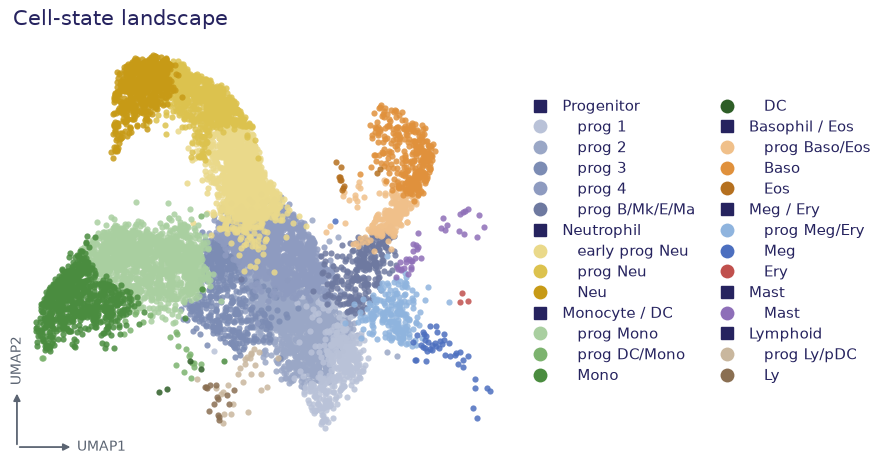

In [7]:
# 21-state palette organized by lineage family (progenitor -> terminal shading)
CT_COL = {
 "prog_1":"#B9C2D8","prog_2":"#9AA7C6","prog_3":"#7C8CB4","prog_4":"#8E9BC0","prog_Baso_Meg_Ery_Mast":"#6E79A0",
 "early_prog_Neu":"#EAD98A","prog_Neu":"#DCC24E","Neu":"#C79A16",
 "prog_Mono":"#A9CFA0","prog_DC_Mono":"#7CB36E","Mono":"#4A8C3F","DC":"#2E5E27",
 "prog_Baso_Eos":"#F0C08A","Baso":"#E0913C","Eos":"#B5701F",
 "prog_Meg_Ery":"#8FB4DE","Meg":"#4C6FBF","Ery":"#C0504D","Mast":"#8E6FB8",
 "prog_Ly_pDC":"#C9B79E","Ly":"#8A6F52"}
ORDER=["prog_2","prog_1","prog_3","prog_4","prog_Baso_Meg_Ery_Mast","early_prog_Neu","prog_Neu",
       "prog_Mono","prog_DC_Mono","prog_Baso_Eos","prog_Meg_Ery","prog_Ly_pDC",
       "Neu","Mono","DC","Baso","Eos","Meg","Ery","Mast","Ly"]
FAMILIES=[("Progenitor",["prog_1","prog_2","prog_3","prog_4","prog_Baso_Meg_Ery_Mast"]),
          ("Neutrophil",["early_prog_Neu","prog_Neu","Neu"]),
          ("Monocyte / DC",["prog_Mono","prog_DC_Mono","Mono","DC"]),
          ("Basophil / Eos",["prog_Baso_Eos","Baso","Eos"]),
          ("Meg / Ery",["prog_Meg_Ery","Meg","Ery"]),("Mast",["Mast"]),("Lymphoid",["prog_Ly_pDC","Ly"])]
PRETTY={"prog_1":"prog 1","prog_2":"prog 2","prog_3":"prog 3","prog_4":"prog 4",
        "prog_Baso_Meg_Ery_Mast":"prog B/Mk/E/Ma","early_prog_Neu":"early prog Neu","prog_Neu":"prog Neu",
        "prog_Mono":"prog Mono","prog_DC_Mono":"prog DC/Mono","prog_Baso_Eos":"prog Baso/Eos",
        "prog_Meg_Ery":"prog Meg/Ery","prog_Ly_pDC":"prog Ly/pDC"}
lab=lambda s: PRETTY.get(s,s)

ctv=obs["cell_type"].astype(str).values
fig,ax=plt.subplots(figsize=(8.6,6.4))
for s in ORDER:
    m=ctv==s; ax.scatter(U[m,0],U[m,1],s=20,c=CT_COL[s],lw=0,alpha=0.85,rasterized=True)
ax.set_aspect("equal"); ax.axis("off")
x0,y0=U[:,0].min()-1.0,U[:,1].min()-1.0
ax.annotate("",xy=(x0+3,y0),xytext=(x0,y0),arrowprops=dict(arrowstyle="-|>",color=GREY,lw=1.3))
ax.annotate("",xy=(x0,y0+3),xytext=(x0,y0),arrowprops=dict(arrowstyle="-|>",color=GREY,lw=1.3))
ax.text(x0+3.2,y0,"UMAP1",fontsize=10,color=GREY,va="center",ha="left")
ax.text(x0,y0+3.3,"UMAP2",fontsize=10,color=GREY,ha="center",va="bottom",rotation=90)
from matplotlib.lines import Line2D
handles,labels=[],[]
for fam,mem in FAMILIES:
    handles.append(Line2D([],[],marker="s",ls="",mfc=INK,mec=INK,ms=8)); labels.append(fam)
    for s in mem:
        handles.append(Line2D([],[],marker="o",ls="",mfc=CT_COL[s],mec="none",ms=10)); labels.append("   "+lab(s))
leg=ax.legend(handles,labels,loc="center left",bbox_to_anchor=(1.0,0.5),frameon=False,
              handletextpad=0.5,labelspacing=0.42,fontsize=10.5,ncol=2,columnspacing=1.2)
for t in leg.get_texts():
    if t.get_text() in {f for f,_ in FAMILIES}: t.set_color(INK)
ax.set_title("Cell-state landscape",loc="left",fontsize=15,pad=8)
fig.tight_layout()
fig.savefig(f"{OUTDIR}/panel_2a_celltype_umap.svg",bbox_inches="tight")
fig.savefig(f"{OUTDIR}/panel_2a_celltype_umap.pdf",dpi=300,bbox_inches="tight")
fig.savefig(f"{OUTDIR}/panel_2a_celltype_umap.png",dpi=600,bbox_inches="tight")
obs.assign(UMAP1=U[:,0],UMAP2=U[:,1])[["UMAP1","UMAP2","cell_type","day","metaclone"]]\
   .to_csv(f"{DATADIR}/fig2a_celltype_umap.csv",index_label="cell")
print("saved panel 2a")

## 6. Panel b — clone-family density over time

Per-metaclone landscape occupancy at Day 2 / 4 / 6, for the nine primed-group metaclones
(neutrophil-primed above, monocyte-primed below; each block ordered by developmental pace).
Colour = **local kNN purity** (The authors' method): for each cell, the number of its 100 nearest
neighbours on the full landscape that belong to the same metaclone, viridis-scaled per metaclone
(floor 5), black-edged points over a faint full-landscape backdrop.

saved panel 2b


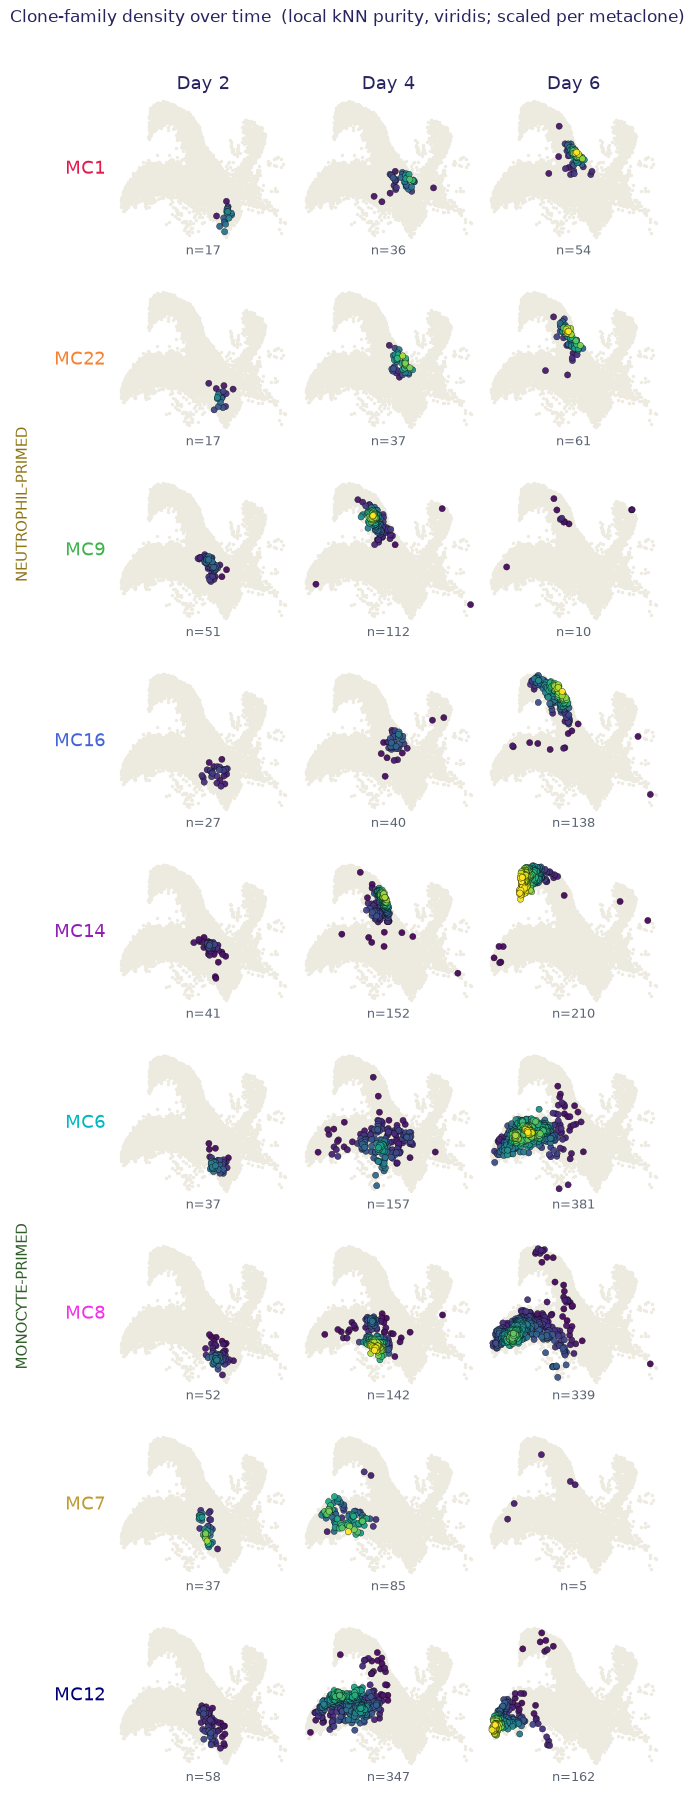

In [9]:
from sklearn.neighbors import NearestNeighbors
adata_plot = A[pd.to_numeric(A.obs["metaclone"],errors="coerce").fillna(-1)!=-1].copy()
full_umap  = adata_plot.obsm["X_umap"]
mc_vals    = pd.to_numeric(adata_plot.obs["metaclone"],errors="coerce").values
day_vals   = adata_plot.obs["day"].values
N_NEIGH=100
nbrs=NearestNeighbors(n_neighbors=N_NEIGH,algorithm="ball_tree").fit(full_umap)

def purity_density(mc, day):
    idx=np.where((mc_vals==mc)&(day_vals==day))[0]
    if len(idx)==0: return None,None,None
    _,ind=nbrs.kneighbors(full_umap[idx]); sset=set(idx.tolist())
    dens=np.array([sum(1 for j in row if j in sset) for row in ind])
    return full_umap[idx],dens,idx

def mc_group_color(m):
    for g,d in GROUPS.items():
        if m in d["mcs"]:
            return d["cmap"][d["mcs"].index(m)], d["branch"]
    return GREY,"-"

prime_mcs = GROUPS["Neutrophil-primed"]["mcs"] + GROUPS["Monocyte-primed"]["mcs"]
mc_vmax={m:max(max([(purity_density(m,dd)[1].max() if purity_density(m,dd)[1] is not None and len(purity_density(m,dd)[1]) else 0) for dd in DAYS]),5) for m in prime_mcs}

xmin,xmax=U[:,0].min()-1,U[:,0].max()+1; ymin,ymax=U[:,1].min()-1,U[:,1].max()+1
fig,axes=plt.subplots(len(prime_mcs),3,figsize=(6.6,2.0*len(prime_mcs)))
for r,m in enumerate(prime_mcs):
    col,_=mc_group_color(m); vmax=mc_vmax[m]
    for c,day in enumerate(DAYS):
        ax=axes[r,c]
        ax.scatter(U[:,0],U[:,1],s=6,c="#EDEAE0",lw=0,rasterized=True,zorder=0)
        coords,dens,idx=purity_density(m,day)
        n=0
        if coords is not None:
            o=dens.argsort()
            ax.scatter(coords[o,0],coords[o,1],c=dens[o],cmap="viridis",s=20,alpha=0.95,
                       edgecolors="black",linewidths=0.25,vmin=0,vmax=vmax,rasterized=True,zorder=2)
            n=len(idx)
        ax.set_aspect("equal"); ax.set_xlim(xmin,xmax); ax.set_ylim(ymin,ymax); ax.axis("off")
        if r==0: ax.set_title(f"Day {day}",fontsize=13,color=INK,pad=4)
        if c==0: ax.text(-0.05,0.5,f"MC{m}",transform=ax.transAxes,fontsize=13,color=col,ha="right",va="center")
        ax.text(0.5,-0.01,f"n={n}",transform=ax.transAxes,fontsize=9,color=GREY,ha="center",va="top")
fig.text(0.008,0.72,"NEUTROPHIL-PRIMED",rotation=90,fontsize=11,color="#8F7614",ha="center",va="center")
fig.text(0.008,0.28,"MONOCYTE-PRIMED",rotation=90,fontsize=11,color="#2E5E27",ha="center",va="center")
fig.suptitle("Clone-family density over time  (local kNN purity, viridis; scaled per metaclone)",
             x=0.5,y=0.995,fontsize=12,color=INK)
fig.tight_layout(rect=[0.035,0,1,0.985]); fig.subplots_adjust(hspace=0.22,wspace=0.04)
fig.savefig(f"{OUTDIR}/panel_2b_density_grid.svg",bbox_inches="tight")
fig.savefig(f"{OUTDIR}/panel_2b_density_grid.pdf",dpi=300,bbox_inches="tight")
fig.savefig(f"{OUTDIR}/panel_2b_density_grid.png",dpi=170,bbox_inches="tight")
print("saved panel 2b")

## 7. Panel c — Palantir pseudotime, lineage trajectories, and branch masks

Left: the landscape coloured by Palantir pseudotime (root = medoid of day-2 `prog_1`, white star),
with the five lineage-branch trajectories traced as pseudotime-binned medoid paths from root to
terminal (Meg / Mast / Baso / Neu / Mono). Right: each branch's Palantir mask cells highlighted on
the landscape. The concept schematic (Stem cell → Trajectory → Metaclone) is assembled separately in
Illustrator. The 3D pseudotime × day × clone-size ridge from the draft is intentionally dropped.

saved panel 2c


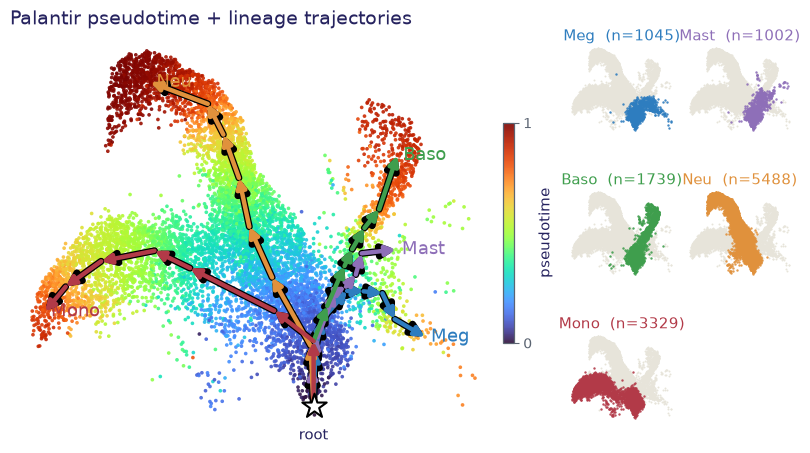

In [10]:
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyArrowPatch

# Root pseudotime coordinate and branch labels
root_i = int(np.nanargmin(obs["pt"].values))
root_xy = U[root_i]
ptv = obs["pt"].values
BRANCHES = ["Meg", "Mast", "Baso", "Neu", "Mono"]

def branch_waypoints(branch, nbins=7):
    idx = np.where(obs[f"mask_{branch}"].values.astype(bool))[0]
    p = ptv[idx]; xy = U[idx]; edges = np.linspace(np.nanmin(p), np.nanmax(p), nbins + 1); pts = [root_xy]
    for b in range(nbins):
        sel = (p >= edges[b]) & (p < edges[b+1])
        if sel.sum() >= 3:
            pts.append(xy[sel][np.argmin(((xy[sel] - np.median(xy[sel], axis=0))**2).sum(1))])
    return np.array(pts)

def jointed_arrow(ax, pts, color, lw=3.2):
    """Segmented arrow: dark-outlined colored segments with an arrowhead on each segment."""
    for a, b in zip(pts[:-1], pts[1:]):
        # outline
        ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=17, lw=lw + 1.8,
                     color="black", shrinkA=0, shrinkB=0, zorder=4, capstyle="round"))
        # inner colored arrow
        ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=14, lw=lw,
                     color=color, shrinkA=0, shrinkB=0, zorder=5, capstyle="round"))

# Construct figure layout
fig = plt.figure(figsize=(10.5, 5.2))
gs = gridspec.GridSpec(2, 5, figure=fig, width_ratios=[1, 1, 1, 0.06, 1.35], height_ratios=[1, 1], wspace=0.12, hspace=0.18)

# Left panel: Palantir pseudotime + jointed segment arrows
axL = fig.add_subplot(gs[:, 0:3])
sc0 = axL.scatter(U[:, 0], U[:, 1], c=ptv, cmap="turbo", s=7, lw=0, alpha=0.9, rasterized=True)

for b in BRANCHES:
    wp = branch_waypoints(b)
    jointed_arrow(axL, wp, BRANCH_COL[b])
    axL.text(wp[-1, 0], wp[-1, 1], f" {b}", fontsize=13, color=BRANCH_COL[b], va="center", ha="left", zorder=6)

axL.scatter([root_xy[0]], [root_xy[1]], marker="*", s=340, c="white", edgecolors="black", lw=1.5, zorder=7)
axL.text(root_xy[0], root_xy[1] - 1.2, "root", fontsize=11, color=INK, ha="center", va="top", zorder=7)
axL.set_aspect("equal")
axL.axis("off")
axL.set_title("Palantir pseudotime + lineage trajectories", loc="left", fontsize=14, pad=6)

cb = fig.colorbar(sc0, ax=axL, fraction=0.035, pad=0.01, shrink=0.55)
cb.set_label("pseudotime", fontsize=11)
cb.ax.tick_params(labelsize=10)
cb.set_ticks([ptv.min(), ptv.max()])
cb.set_ticklabels(["0", "1"])

# Right panel: Individual branch cell masks
gsR = gridspec.GridSpecFromSubplotSpec(3, 2, subplot_spec=gs[:, 4], wspace=0.08, hspace=0.28)
for i, b in enumerate(BRANCHES):
    ax = fig.add_subplot(gsR[i])
    m = obs[f"mask_{b}"].values.astype(bool)
    ax.scatter(U[~m, 0], U[~m, 1], s=2, c="#E7E4DA", lw=0, rasterized=True)
    ax.scatter(U[m, 0], U[m, 1], s=3, c=BRANCH_COL[b], lw=0, alpha=0.9, rasterized=True)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{b}  (n={int(m.sum())})", fontsize=11, color=BRANCH_COL[b], pad=1)

fig.add_subplot(gsR[5]).axis("off")

# Save outputs
# fig.savefig(f"{OUTDIR}/panel_2c_pseudotime_branches.svg", bbox_inches="tight")
# fig.savefig(f"{OUTDIR}/panel_2c_pseudotime_branches.pdf", dpi=300, bbox_inches="tight")
# fig.savefig(f"{OUTDIR}/panel_2c_pseudotime_branches.png", dpi=190, bbox_inches="tight")

# Export source data
pd.DataFrame({"UMAP1": U[:, 0], "UMAP2": U[:, 1], "pseudotime": ptv,
              **{f"mask_{b}": obs[f"mask_{b}"].values for b in BRANCHES}}, index=obs.index) \
   .to_csv(f"{DATADIR}/fig2c_pseudotime_masks.csv", index_label="cell")

print("saved panel 2c")
if "host" in globals() and hasattr(host, "view_image"):
    host.view_image(f"{OUTDIR}/panel_2c_pseudotime_branches.png")

## 8. Panels d & e — developmental pace at matched lineage output

For each output-matched primed group, the left bars show differentiated-output composition and
the right violins show Palantir pseudotime at Day 2/4/6, with per-day Kruskal-Wallis tests across
metaclones. Panel d is neutrophil-primed and panel e is monocyte-primed.

saved panel 2d & standalone legends
saved panel 2e & standalone legends


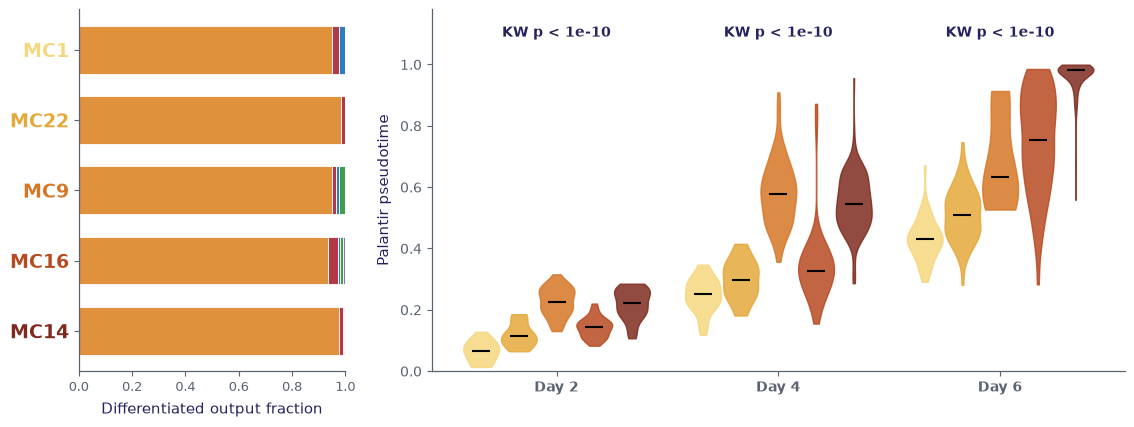

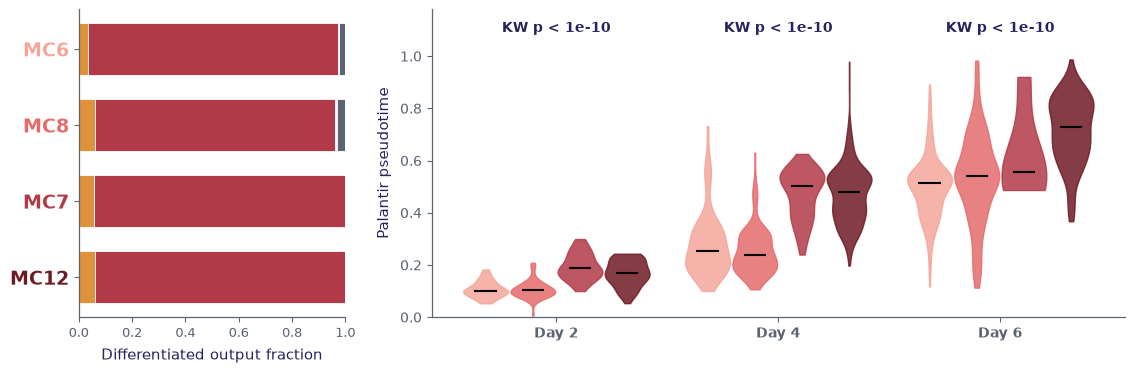

In [11]:
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal

# ---- Refined publication color palettes for pace gradients ----
PACE_PALETTES = {
    "Neutrophil-primed": ["#F5D77F", "#E5A83B", "#D67727", "#B84A21", "#7E2B1E"],  # Warm Amber -> Burnt Terracotta
    "Monocyte-primed":   ["#F4A69A", "#E56B6B", "#B23A48", "#6E1A24"],             # Mint -> Deep Forest Emerald
}

# Update GROUPS color maps
for g, d in GROUPS.items():
    if g in PACE_PALETTES:
        d["cmap"] = PACE_PALETTES[g]

def pval_str(p):
    if np.isnan(p): return "n.s."
    return "p < 1e-10" if p < 1e-10 else f"p = {p:.0e}".replace("e-0", "e-")

def pace_stats(mcs):
    rows = []
    for day in DAYS:
        samples = [Cc[(Cc["metaclone"] == m) & (Cc["day"] == day)]["pt"].dropna().values for m in mcs]
        samples = [s for s in samples if len(s) >= 3]
        H, p = (kruskal(*samples) if len(samples) >= 2 else (np.nan, np.nan))
        meds = [np.nanmedian(Cc[(Cc["metaclone"] == m) & (Cc["day"] == day)]["pt"]) for m in mcs]
        rows.append(dict(day=day, H=round(H, 2), p=p, n_groups=len(samples),
                         pt_spread=round(np.nanmax(meds) - np.nanmin(meds), 3)))
    return pd.DataFrame(rows)

def save_standalone_legend(handles, filename_base, ncol=1, title="", fontsize=10.5):
    """Helper to save a standalone legend figure tightly cropped to content."""
    fig_leg = plt.figure(figsize=(4, 2))
    leg = fig_leg.legend(handles=handles, loc="center", frameon=False, ncol=ncol, 
                         title=title if title else None, title_fontsize=fontsize + 0.5, 
                         fontsize=fontsize, handlelength=1.2, columnspacing=1.2)
    fig_leg.canvas.draw()
    bbox = leg.get_window_extent().transformed(fig_leg.dpi_scale_trans.inverted())
    fig_leg.savefig(f"{filename_base}.pdf", bbox_inches=bbox, dpi=300)
    fig_leg.savefig(f"{filename_base}.png", bbox_inches=bbox, dpi=300)
    fig_leg.savefig(f"{filename_base}.svg", bbox_inches=bbox)
    plt.close(fig_leg)

def pace_panel(group_name, save_key):
    d = GROUPS[group_name]
    mcs = d["mcs"]
    cmap = d["cmap"]
    br = d["branch"]
    
    P = output_profile(mcs)
    st = pace_stats(mcs)
    
    # Wider figure layout with larger width ratio for violin subplots (1 : 2.6)
    fig = plt.figure(figsize=(13.5, 0.7 * len(mcs) + 1.2))
    gs = gridspec.GridSpec(1, 2, width_ratios=[1, 2.6], wspace=0.18)
    
    # -------------------------------------------------------------
    # Left subplot: Differentiated output composition
    # -------------------------------------------------------------
    axb = fig.add_subplot(gs[0])
    ypos = np.arange(len(mcs))[::-1]
    left = np.zeros(len(mcs))
    
    bar_handles = []
    for cat in OUT_ORDER:
        vals = P[cat].values
        b = axb.barh(ypos, vals, left=left, color=OUT_COL[cat], edgecolor="white", lw=0.6, height=0.68)
        left = left + vals
        if (vals > 0.02).any():
            bar_handles.append(Patch(facecolor=OUT_COL[cat], edgecolor="white", label=cat))
        
    axb.set_yticks(ypos)
    axb.set_yticklabels([f"MC{m}" for m in mcs])
    axb.set_xlim(0, 1)
    axb.set_xlabel("Differentiated output fraction", fontsize=10.5, labelpad=6)
    axb.spines[["top", "right"]].set_visible(False)
    axb.tick_params(axis="x", labelsize=9.5)
    
    # Format y-axis MC labels
    for i, label in enumerate(axb.get_yticklabels()):
        label.set_color(cmap[i])
        label.set_fontsize(14)
        label.set_fontweight("bold")
        
    # -------------------------------------------------------------
    # Right subplot: Pseudotime pace violins (Wider format)
    # -------------------------------------------------------------
    axv = fig.add_subplot(gs[1])
    W = 0.85 / len(mcs)
    
    for c, day in enumerate(DAYS):
        for i, m in enumerate(mcs):
            v = Cc[(Cc["metaclone"] == m) & (Cc["day"] == day)]["pt"].dropna().values
            if len(v) < 3: continue
            xc = c + (i - (len(mcs) - 1) / 2) * W
            parts = axv.violinplot([v], positions=[xc], widths=W * 0.95, showmedians=True, showextrema=False)
            for b in parts["bodies"]:
                b.set_facecolor(cmap[i])
                b.set_edgecolor(cmap[i])
                b.set_linewidth(1.0)
                b.set_alpha(0.85)
            parts["cmedians"].set_color("black")
            parts["cmedians"].set_linewidth(1.5)
            
        axv.text(c, 1.08, f"KW {pval_str(st[st.day == day].iloc[0]['p'])}", ha="center", va="bottom", fontsize=10.0, fontweight="bold", color=INK)
        
    axv.set_xticks(range(len(DAYS)))
    axv.set_xticklabels([f"Day {x}" for x in DAYS], fontsize=11.0, fontweight="bold")
    axv.set_ylabel("Palantir pseudotime", fontsize=11.0, labelpad=6)
    axv.set_ylim(0, 1.18)
    axv.spines[["top", "right"]].set_visible(False)
    axv.tick_params(labelsize=10.0)
    
    # Save main figure (without embedded legends)
    fig.savefig(f"{OUTDIR}/panel_{save_key}.svg", bbox_inches="tight")
    fig.savefig(f"{OUTDIR}/panel_{save_key}.pdf", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUTDIR}/panel_{save_key}.png", dpi=300, bbox_inches="tight")
    
    # -------------------------------------------------------------
    # Save Standalone Legends Separately
    # -------------------------------------------------------------
    # 1. Output composition legend
    save_standalone_legend(bar_handles, f"{OUTDIR}/panel_{save_key}_legend_output", ncol=len(bar_handles), fontsize=10)
    
    # 2. Metaclone pace legend
    pace_handles = [Patch(facecolor=cmap[i], edgecolor=cmap[i], label=f"MC{m} (D6 pt {SURVEY.loc[m, 'pt_D6']:.2f})") for i, m in enumerate(mcs)]
    save_standalone_legend(pace_handles, f"{OUTDIR}/panel_{save_key}_legend_pace", ncol=1, title="", fontsize=10)
    
    lg = save_key.split("_")[0][-1]
    P.to_csv(f"{DATADIR}/fig2{lg}_output_composition.csv", index_label="metaclone")
    st.to_csv(f"{DATADIR}/fig2{lg}_perday_kruskal.csv", index=False)
    Cc[Cc["metaclone"].isin(mcs)][["metaclone", "day", "pt", "LARRY_ID"]].to_csv(f"{DATADIR}/fig2{lg}_pseudotime_by_mc_day.csv", index_label="cell")
    return fig

_=pace_panel("Neutrophil-primed", "2d_neu_pace"); print("saved panel 2d & standalone legends")
_=pace_panel("Monocyte-primed", "2e_mono_pace"); print("saved panel 2e & standalone legends")

saved panel 2d & standalone legends
saved panel 2e & standalone legends


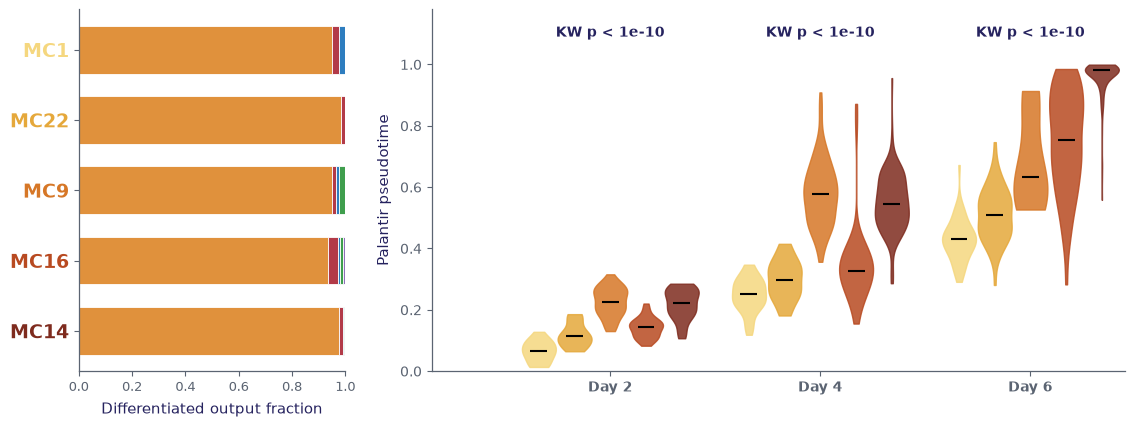

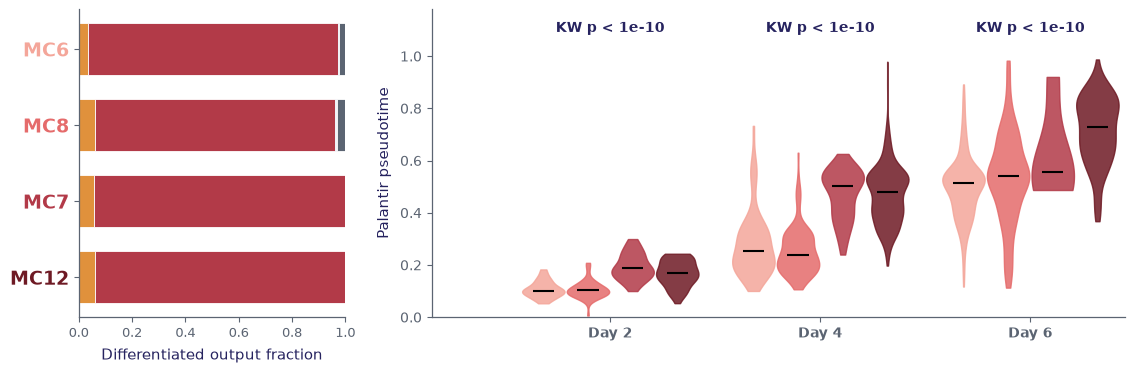

In [12]:
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal

# ---- Refined publication color palettes for pace gradients ----
PACE_PALETTES = {
    "Neutrophil-primed": ["#F5D77F", "#E5A83B", "#D67727", "#B84A21", "#7E2B1E"],  # Warm Amber -> Burnt Terracotta
    "Monocyte-primed":   ["#F4A69A", "#E56B6B", "#B23A48", "#6E1A24"],             # Mint -> Deep Forest Emerald
}

# Update GROUPS color maps
for g, d in GROUPS.items():
    if g in PACE_PALETTES:
        d["cmap"] = PACE_PALETTES[g]

def pval_str(p):
    if np.isnan(p): return "n.s."
    return "p < 1e-10" if p < 1e-10 else f"p = {p:.0e}".replace("e-0", "e-")

def pace_stats(mcs):
    rows = []
    for day in DAYS:
        samples = [Cc[(Cc["metaclone"] == m) & (Cc["day"] == day)]["pt"].dropna().values for m in mcs]
        samples = [s for s in samples if len(s) >= 3]
        H, p = (kruskal(*samples) if len(samples) >= 2 else (np.nan, np.nan))
        meds = [np.nanmedian(Cc[(Cc["metaclone"] == m) & (Cc["day"] == day)]["pt"]) for m in mcs]
        rows.append(dict(day=day, H=round(H, 2), p=p, n_groups=len(samples),
                         pt_spread=round(np.nanmax(meds) - np.nanmin(meds), 3)))
    return pd.DataFrame(rows)

def save_standalone_legend(handles, filename_base, ncol=1, title="", fontsize=10.5):
    """Helper to save a standalone legend figure tightly cropped to content."""
    fig_leg = plt.figure(figsize=(4, 2))
    leg = fig_leg.legend(handles=handles, loc="center", frameon=False, ncol=ncol, 
                         title=title if title else None, title_fontsize=fontsize + 0.5, 
                         fontsize=fontsize, handlelength=1.2, columnspacing=1.2)
    fig_leg.canvas.draw()
    bbox = leg.get_window_extent().transformed(fig_leg.dpi_scale_trans.inverted())
    fig_leg.savefig(f"{filename_base}.pdf", bbox_inches=bbox, dpi=300)
    fig_leg.savefig(f"{filename_base}.png", bbox_inches=bbox, dpi=300)
    fig_leg.savefig(f"{filename_base}.svg", bbox_inches=bbox)
    plt.close(fig_leg)

def pace_panel(group_name, save_key):
    d = GROUPS[group_name]
    mcs = d["mcs"]
    cmap = d["cmap"]
    br = d["branch"]
    
    P = output_profile(mcs)
    st = pace_stats(mcs)
    
    # Wider figure layout with larger width ratio for violin subplots (1 : 2.6)
    fig = plt.figure(figsize=(13.5, 0.7 * len(mcs) + 1.2))
    gs = gridspec.GridSpec(1, 2, width_ratios=[1, 2.6], wspace=0.18)
    
    # -------------------------------------------------------------
    # Left subplot: Differentiated output composition
    # -------------------------------------------------------------
    axb = fig.add_subplot(gs[0])
    ypos = np.arange(len(mcs))[::-1]
    left = np.zeros(len(mcs))
    
    bar_handles = []
    for cat in OUT_ORDER:
        vals = P[cat].values
        b = axb.barh(ypos, vals, left=left, color=OUT_COL[cat], edgecolor="white", lw=0.6, height=0.68)
        left = left + vals
        if (vals > 0.02).any():
            bar_handles.append(Patch(facecolor=OUT_COL[cat], edgecolor="white", label=cat))
        
    axb.set_yticks(ypos)
    axb.set_yticklabels([f"MC{m}" for m in mcs])
    axb.set_xlim(0, 1)
    axb.set_xlabel("Differentiated output fraction", fontsize=10.5, labelpad=6)
    axb.spines[["top", "right"]].set_visible(False)
    axb.tick_params(axis="x", labelsize=9.5)
    
    # Format y-axis MC labels
    for i, label in enumerate(axb.get_yticklabels()):
        label.set_color(cmap[i])
        label.set_fontsize(14)
        label.set_fontweight("bold")
        
    # -------------------------------------------------------------
    # Right subplot: Pseudotime pace violins (Wider format)
    # -------------------------------------------------------------
    axv = fig.add_subplot(gs[1])
    W = 0.85 / len(mcs)
    
    for c, day in enumerate(DAYS):
        for i, m in enumerate(mcs):
            v = Cc[(Cc["metaclone"] == m) & (Cc["day"] == day)]["pt"].dropna().values
            if len(v) < 3: continue
            xc = c + (i - (len(mcs) - 1) / 2) * W
            parts = axv.violinplot([v], positions=[xc], widths=W * 0.95, showmedians=True, showextrema=False)
            for b in parts["bodies"]:
                b.set_facecolor(cmap[i])
                b.set_edgecolor(cmap[i])
                b.set_linewidth(1.0)
                b.set_alpha(0.85)
            parts["cmedians"].set_color("black")
            parts["cmedians"].set_linewidth(1.5)
            
        axv.text(c, 1.08, f"KW {pval_str(st[st.day == day].iloc[0]['p'])}", ha="center", va="bottom", fontsize=10.0, fontweight="bold", color=INK)
        
    axv.set_xticks(range(len(DAYS)))
    axv.set_xticklabels([f"Day {x}" for x in DAYS], fontsize=11.0, fontweight="bold")
    axv.set_ylabel("Palantir pseudotime", fontsize=11.0, labelpad=6)
    axv.set_ylim(0, 1.18)
    
    # Add spacing between y-axis line and Day 2 violins
    axv.set_xlim(-0.85, len(DAYS) - 0.55)
    
    axv.spines[["top", "right"]].set_visible(False)
    axv.tick_params(labelsize=10.0)
    
    # Save main figure (without embedded legends)
    fig.savefig(f"{OUTDIR}/panel_{save_key}.svg", bbox_inches="tight")
    fig.savefig(f"{OUTDIR}/panel_{save_key}.pdf", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUTDIR}/panel_{save_key}.png", dpi=300, bbox_inches="tight")
    
    # -------------------------------------------------------------
    # Save Standalone Legends Separately
    # -------------------------------------------------------------
    # 1. Output composition legend
    save_standalone_legend(bar_handles, f"{OUTDIR}/panel_{save_key}_legend_output", ncol=len(bar_handles), fontsize=10)
    
    # 2. Metaclone pace legend
    pace_handles = [Patch(facecolor=cmap[i], edgecolor=cmap[i], label=f"MC{m}") for i, m in enumerate(mcs)]
    save_standalone_legend(pace_handles, f"{OUTDIR}/panel_{save_key}_legend_pace", ncol=1, title="", fontsize=10)
    
    lg = save_key.split("_")[0][-1]
    P.to_csv(f"{DATADIR}/fig2{lg}_output_composition.csv", index_label="metaclone")
    st.to_csv(f"{DATADIR}/fig2{lg}_perday_kruskal.csv", index=False)
    Cc[Cc["metaclone"].isin(mcs)][["metaclone", "day", "pt", "LARRY_ID"]].to_csv(f"{DATADIR}/fig2{lg}_pseudotime_by_mc_day.csv", index_label="cell")
    return fig

_=pace_panel("Neutrophil-primed", "2d_neu_pace"); print("saved panel 2d & standalone legends")
_=pace_panel("Monocyte-primed", "2e_mono_pace"); print("saved panel 2e & standalone legends")

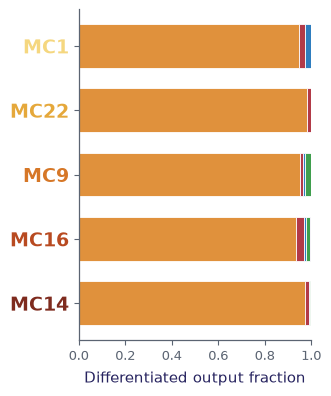

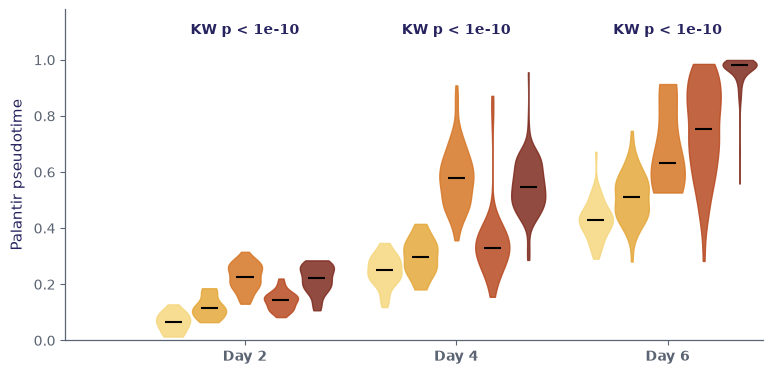

saved panel 2d left & right separately


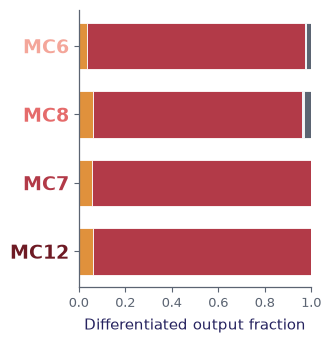

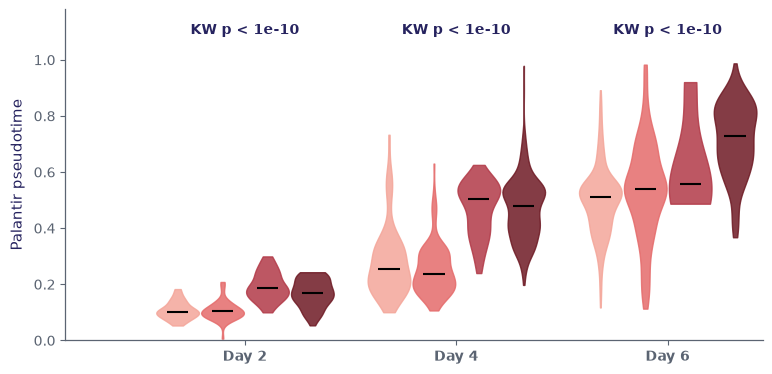

saved panel 2e left & right separately


In [13]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from scipy.stats import kruskal

# ---- Refined publication color palettes for pace gradients ----
PACE_PALETTES = {
    "Neutrophil-primed": ["#F5D77F", "#E5A83B", "#D67727", "#B84A21", "#7E2B1E"],  # Warm Amber -> Burnt Terracotta
    "Monocyte-primed":   ["#F4A69A", "#E56B6B", "#B23A48", "#6E1A24"],             # Mint -> Deep Forest Emerald
}

# Update GROUPS color maps
for g, d in GROUPS.items():
    if g in PACE_PALETTES:
        d["cmap"] = PACE_PALETTES[g]

def pval_str(p):
    if np.isnan(p): return "n.s."
    return "p < 1e-10" if p < 1e-10 else f"p = {p:.0e}".replace("e-0", "e-")

def pace_stats(mcs):
    rows = []
    for day in DAYS:
        samples = [Cc[(Cc["metaclone"] == m) & (Cc["day"] == day)]["pt"].dropna().values for m in mcs]
        samples = [s for s in samples if len(s) >= 3]
        H, p = (kruskal(*samples) if len(samples) >= 2 else (np.nan, np.nan))
        meds = [np.nanmedian(Cc[(Cc["metaclone"] == m) & (Cc["day"] == day)]["pt"]) for m in mcs]
        rows.append(dict(day=day, H=round(H, 2), p=p, n_groups=len(samples),
                         pt_spread=round(np.nanmax(meds) - np.nanmin(meds), 3)))
    return pd.DataFrame(rows)

def pace_panel_separate(group_name, save_key):
    d = GROUPS[group_name]
    mcs = d["mcs"]
    cmap = d["cmap"]
    br = d["branch"]
    
    P = output_profile(mcs)
    st = pace_stats(mcs)
    
    # -------------------------------------------------------------
    # 1. LEFT PANEL: Differentiated output composition (Separate Figure)
    # -------------------------------------------------------------
    fig_left, axb = plt.subplots(figsize=(3, 0.7 * len(mcs) + 0.8))
    ypos = np.arange(len(mcs))[::-1]
    left = np.zeros(len(mcs))
    
    for cat in OUT_ORDER:
        vals = P[cat].values
        axb.barh(ypos, vals, left=left, color=OUT_COL[cat], edgecolor="white", lw=0.6, height=0.68)
        left = left + vals
        
    axb.set_yticks(ypos)
    axb.set_yticklabels([f"MC{m}" for m in mcs])
    axb.set_xlim(0, 1)
    axb.set_xlabel("Differentiated output fraction", fontsize=10.5, labelpad=6)
    axb.spines[["top", "right"]].set_visible(False)
    axb.tick_params(axis="x", labelsize=9.5)
    
    # Format y-axis MC labels (bold, large, group colored)
    for i, label in enumerate(axb.get_yticklabels()):
        label.set_color(cmap[i])
        label.set_fontsize(14)
        label.set_fontweight("bold")
        
    fig_left.savefig(f"{OUTDIR}/panel_{save_key}_left_output.pdf", dpi=300, bbox_inches="tight")
    fig_left.savefig(f"{OUTDIR}/panel_{save_key}_left_output.png", dpi=300, bbox_inches="tight")
    fig_left.savefig(f"{OUTDIR}/panel_{save_key}_left_output.svg", bbox_inches="tight")
    plt.show()

    # -------------------------------------------------------------
    # 2. RIGHT PANEL: Pseudotime pace violins (Separate Figure)
    # -------------------------------------------------------------
    fig_right, axv = plt.subplots(figsize=(9.0, 0.7 * 5 + 0.8))
    W = 0.85 / len(mcs)
    
    for c, day in enumerate(DAYS):
        for i, m in enumerate(mcs):
            v = Cc[(Cc["metaclone"] == m) & (Cc["day"] == day)]["pt"].dropna().values
            if len(v) < 3: continue
            xc = c + (i - (len(mcs) - 1) / 2) * W
            parts = axv.violinplot([v], positions=[xc], widths=W * 0.95, showmedians=True, showextrema=False)
            for b in parts["bodies"]:
                b.set_facecolor(cmap[i])
                b.set_edgecolor(cmap[i])
                b.set_linewidth(1.0)
                b.set_alpha(0.85)
            parts["cmedians"].set_color("black")
            parts["cmedians"].set_linewidth(1.5)
            
        axv.text(c, 1.08, f"KW {pval_str(st[st.day == day].iloc[0]['p'])}", ha="center", va="bottom", fontsize=10.0, fontweight="bold", color=INK)
        
    axv.set_xticks(range(len(DAYS)))
    axv.set_xticklabels([f"Day {x}" for x in DAYS], fontsize=11.0, fontweight="bold")
    axv.set_ylabel("Palantir pseudotime", fontsize=11.0, labelpad=6)
    axv.set_ylim(0, 1.18)
    axv.set_xlim(-0.85, len(DAYS) - 0.55)  # Spacing between y-axis and Day 2 violins
    
    axv.spines[["top", "right"]].set_visible(False)
    axv.tick_params(labelsize=10.0)
    
    fig_right.savefig(f"{OUTDIR}/panel_{save_key}_right_violins.pdf", dpi=300, bbox_inches="tight")
    fig_right.savefig(f"{OUTDIR}/panel_{save_key}_right_violins.png", dpi=300, bbox_inches="tight")
    fig_right.savefig(f"{OUTDIR}/panel_{save_key}_right_violins.svg", bbox_inches="tight")
    plt.show()

    # Export source data
    lg = save_key.split("_")[0][-1]
    P.to_csv(f"{DATADIR}/fig2{lg}_output_composition.csv", index_label="metaclone")
    st.to_csv(f"{DATADIR}/fig2{lg}_perday_kruskal.csv", index=False)
    Cc[Cc["metaclone"].isin(mcs)][["metaclone", "day", "pt", "LARRY_ID"]].to_csv(f"{DATADIR}/fig2{lg}_pseudotime_by_mc_day.csv", index_label="cell")

# Generate separate outputs for both groups
pace_panel_separate("Neutrophil-primed", "2d_neu_pace"); print("saved panel 2d left & right separately")
pace_panel_separate("Monocyte-primed", "2e_mono_pace"); print("saved panel 2e left & right separately")


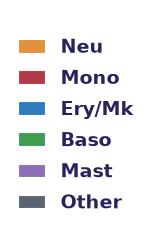

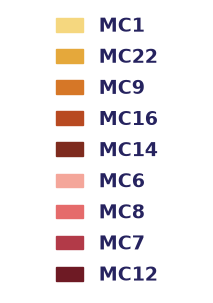

saved tightly cropped universal vertical legends (Lineage Output & Metaclones)


In [14]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# -----------------------------------------------------------------------------
# Helper function to save tightly cropped legend figures without extra whitespace
# -----------------------------------------------------------------------------
def save_tight_legend(fig, leg, filename_base, dpi=300):
    fig.canvas.draw()
    bbox = leg.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
    fig.savefig(f"{filename_base}.pdf", dpi=dpi, bbox_inches=bbox)
    fig.savefig(f"{filename_base}.png", dpi=dpi, bbox_inches=bbox)
    fig.savefig(f"{filename_base}.svg", dpi=dpi, bbox_inches=bbox)

# -----------------------------------------------------------------------------
# 1. Universal Legend for Differentiated Lineage Output (Left Plot)
# -----------------------------------------------------------------------------
lineage_handles = [
    Patch(facecolor=OUT_COL[cat], edgecolor="white", lw=0.8, label=cat) 
    for cat in OUT_ORDER if cat in OUT_COL
]

fig_leg_left, ax_left = plt.subplots(figsize=(1.5, 3.0))
ax_left.axis("off")

leg_left = ax_left.legend(
    handles=lineage_handles,
    loc="center",
    frameon=False,
    ncol=1,  # Vertical layout
    fontsize=14,
    handlelength=1.4,
    labelspacing=0.6
)

for text in leg_left.get_texts():
    text.set_fontweight("bold")
    text.set_color(INK)

save_tight_legend(fig_leg_left, leg_left, f"{OUTDIR}/universal_legend_lineage_output")
plt.show()

# -----------------------------------------------------------------------------
# 2. Universal Legend for Metaclones (Right Violin Plot)
# -----------------------------------------------------------------------------
mc_handles = []

for group_name in ["Neutrophil-primed", "Monocyte-primed"]:
    d = GROUPS[group_name]
    mcs = d["mcs"]
    cmap = d["cmap"]
    for i, m in enumerate(mcs):
        mc_handles.append(Patch(facecolor=cmap[i], edgecolor=cmap[i], label=f"MC{m}"))

fig_leg_right, ax_right = plt.subplots(figsize=(2.5, 3.5))
ax_right.axis("off")

leg_right = ax_right.legend(
    handles=mc_handles,
    loc="center",
    frameon=False,
    ncol=1,  # Vertical layout
    fontsize=14,
    handlelength=1.4,
    labelspacing=0.6
)

for i, text in enumerate(leg_right.get_texts()):
    text.set_fontweight("bold")

save_tight_legend(fig_leg_right, leg_right, f"{OUTDIR}/universal_legend_metaclone_pace")
plt.show()

print("saved tightly cropped universal vertical legends (Lineage Output & Metaclones)")

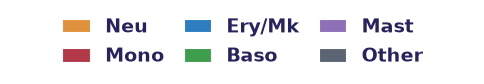

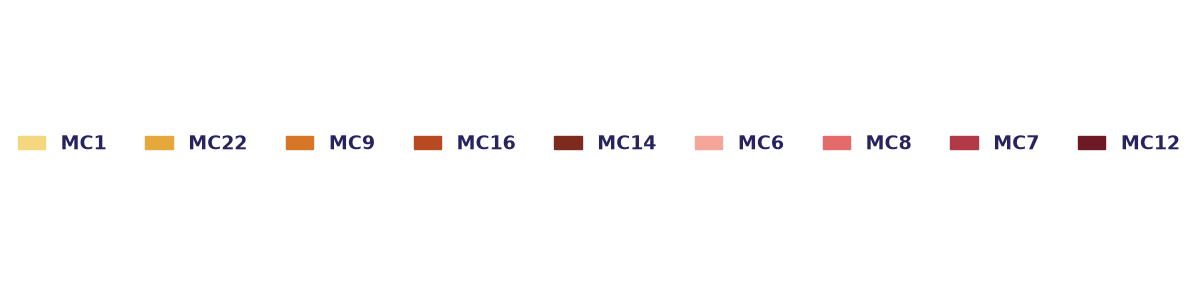

saved horizontal lineage output legend & vertical metaclone pace legend


In [15]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# -----------------------------------------------------------------------------
# Helper function to save tightly cropped legend figures without extra whitespace
# -----------------------------------------------------------------------------
def save_tight_legend(fig, leg, filename_base, dpi=300):
    fig.canvas.draw()
    bbox = leg.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
    fig.savefig(f"{filename_base}.pdf", dpi=dpi, bbox_inches=bbox)
    fig.savefig(f"{filename_base}.png", dpi=dpi, bbox_inches=bbox)
    fig.savefig(f"{filename_base}.svg", dpi=dpi, bbox_inches=bbox)

# -----------------------------------------------------------------------------
# 1. Universal Legend for Differentiated Lineage Output (Left Plot) - Horizontal
# -----------------------------------------------------------------------------
lineage_handles = [
    Patch(facecolor=OUT_COL[cat], edgecolor="white", lw=0.8, label=cat) 
    for cat in OUT_ORDER if cat in OUT_COL
]

fig_leg_left, ax_left = plt.subplots(figsize=(6.0, 0.5))
ax_left.axis("off")

leg_left = ax_left.legend(
    handles=lineage_handles,
    loc="center",
    frameon=False,
    ncol=len(lineage_handles)/2,  # Horizontal layout
    fontsize=14,
    handlelength=1.4,
    columnspacing=1
)

for text in leg_left.get_texts():
    text.set_fontweight("bold")
    text.set_color(INK)

save_tight_legend(fig_leg_left, leg_left, f"{OUTDIR}/universal_legend_lineage_output")
plt.show()

# -----------------------------------------------------------------------------
# 2. Universal Legend for Metaclones (Right Violin Plot) - Vertical
# -----------------------------------------------------------------------------
mc_handles = []

for group_name in ["Neutrophil-primed", "Monocyte-primed"]:
    d = GROUPS[group_name]
    mcs = d["mcs"]
    cmap = d["cmap"]
    for i, m in enumerate(mcs):
        mc_handles.append(Patch(facecolor=cmap[i], edgecolor=cmap[i], label=f"MC{m}"))

fig_leg_right, ax_right = plt.subplots(figsize=(2.5, 3.5))
ax_right.axis("off")

leg_right = ax_right.legend(
    handles=mc_handles,
    loc="center",
    frameon=False,
    ncol=9,  # Vertical layout
    fontsize=14,
    handlelength=1.4,
    labelspacing=0.6
)

for i, text in enumerate(leg_right.get_texts()):
    text.set_fontweight("bold")

save_tight_legend(fig_leg_right, leg_right, f"{OUTDIR}/universal_legend_metaclone_pace")
plt.show()

print("saved horizontal lineage output legend & vertical metaclone pace legend")

## 8b. Split panels (one plot per cell, one file per plot)

Per the authors' standing rule: **no cell renders more than one plot.** Each sub-plot from the
composite panels above (8) is rebuilt in its own dedicated cell below and written to its
own file under `Figure/fig2/panels/split/` (svg + pdf + png), with a matching per-panel
source CSV under `Figure/fig2/data/split/`. Helper *function definitions* (no plotting)
are shared in one setup cell; every subsequent cell calls exactly one plotting function
once. Format matches the draft references: branch-colored title (`<group> MCs: Branch <X>`),
a vertical turbo pseudotime colorbar, distinct per-metaclone hues, and Kruskal-Wallis
significance stars. Groups are defined on the corrected trajectory object
(Neu = MC1/22/9/16/14, Mono = MC6/8/9/12 ordered slow->fast by D6 pseudotime).

In [16]:
# --- shared HELPERS for the split panels (function defs only -- no plot is rendered here) ---
import os
from matplotlib.patches import Patch
from scipy.stats import kruskal
from scipy.interpolate import splprep, splev
SPLIT = f"{OUTDIR}/split"; DATADIR_S = f"{DATADIR}/split"
os.makedirs(SPLIT, exist_ok=True); os.makedirs(DATADIR_S, exist_ok=True)

def star(p):
    if np.isnan(p): return "n.s."
    return "****" if p<1e-4 else "***" if p<1e-3 else "**" if p<1e-2 else "*" if p<0.05 else "n.s."

def pace_stats(mcs):
    rows=[]
    for day in DAYS:
        s=[Cc[(Cc.metaclone==m)&(Cc.day==day)]["pt"].dropna().values for m in mcs]
        s=[x for x in s if len(x)>=3]
        H,p=(kruskal(*s) if len(s)>=2 else (np.nan,np.nan))
        meds=[np.nanmedian(Cc[(Cc.metaclone==m)&(Cc.day==day)]["pt"]) for m in mcs]
        rows.append(dict(day=day,H=round(H,2) if not np.isnan(H) else np.nan,p=p,
                         n_groups=len(s),pt_spread=round(np.nanmax(meds)-np.nanmin(meds),3)))
    return pd.DataFrame(rows)

def _save3(fig,key):
    for ext in ("svg","pdf","png"):
        fig.savefig(f"{SPLIT}/{key}.{ext}",dpi=300 if ext!="png" else 200,bbox_inches="tight")

def composition_panel(group_name,key):
    """Renders exactly ONE plot: the output-composition bars for one primed group."""
    d=GROUPS[group_name]; mcs=d["mcs"]; P=output_profile(mcs)
    fig=plt.figure(figsize=(2.4,0.55*len(mcs)+1.4)); ax=fig.add_subplot(111)
    yp=np.arange(len(mcs))[::-1]; left=np.zeros(len(mcs))
    for cat in OUT_ORDER:
        v=P[cat].values
        ax.barh(yp,v,left=left,color=OUT_COL[cat],edgecolor="white",lw=0.4,
                label=cat if (v>0.02).any() else None,height=0.72); left=left+v
    ax.set_yticks(yp); ax.set_yticklabels([f"MC{m}" for m in mcs],fontsize=9)
    for i in range(len(mcs)): ax.get_yticklabels()[i].set_color(MC_COLOR[mcs[i]])
    ax.set_xlim(0,1); ax.set_xlabel("differentiated output",fontsize=8)
    ax.set_title("output composition",loc="left",fontsize=9,pad=4,color=INK)
    ax.spines[["top","right"]].set_visible(False); ax.tick_params(labelsize=7)
    ax.legend(loc="upper center",bbox_to_anchor=(0.5,-0.13),ncol=3,frameon=False,
              fontsize=6,handlelength=1,columnspacing=0.9)
    fig.tight_layout(); _save3(fig,key)
    P.to_csv(f"{DATADIR_S}/{key.split('panel_')[1].replace('_composition','')}_output_composition.csv",index_label="metaclone")
    return fig

def pace_panel(group_name,key):
    """Renders exactly ONE plot: the developmental-pace violins for one primed group."""
    d=GROUPS[group_name]; mcs=d["mcs"]; br=d["branch"]; st=pace_stats(mcs)
    fig=plt.figure(figsize=(6.4,4.2)); ax=fig.add_axes([0.20,0.13,0.75,0.72])
    W=0.8/len(mcs)
    for c,day in enumerate(DAYS):
        for i,m in enumerate(mcs):
            v=Cc[(Cc.metaclone==m)&(Cc.day==day)]["pt"].dropna().values
            if len(v)<3: continue
            xc=c+(i-(len(mcs)-1)/2)*W
            parts=ax.violinplot([v],positions=[xc],widths=W*0.95,showmedians=True,showextrema=False)
            for b in parts["bodies"]:
                b.set_facecolor(MC_COLOR[m]); b.set_edgecolor("none"); b.set_alpha(0.92)
            parts["cmedians"].set_color("black"); parts["cmedians"].set_linewidth(1.1)
        p=st[st.day==day].iloc[0]["p"]
        xL=c-(len(mcs)-1)/2*W; xR=c+(len(mcs)-1)/2*W
        ax.plot([xL,xL,xR,xR],[1.05,1.075,1.075,1.05],color=GREY,lw=0.9,clip_on=False)
        ax.text(c,1.082,star(p),ha="center",va="bottom",fontsize=12,color=INK,fontweight="bold")
    ax.set_xticks(range(len(DAYS))); ax.set_xticklabels([f"Day {x}" for x in DAYS],fontsize=9)
    ax.set_ylabel("Palantir pseudotime",fontsize=9); ax.set_ylim(0,1.17)
    ax.set_xlim(-0.5,len(DAYS)-0.5)
    ax.spines[["top","right"]].set_visible(False); ax.tick_params(labelsize=8)
    bc=BRANCH_COL[br]
    t1=ax.text(0.0,1.12,f"{group_name} MCs:  ",transform=ax.transAxes,fontsize=11,
               fontweight="bold",color=INK,va="bottom",ha="left")
    fig.canvas.draw()
    bb=t1.get_window_extent(fig.canvas.get_renderer()).transformed(ax.transAxes.inverted())
    ax.text(bb.x1,1.12,f"Branch {br}",transform=ax.transAxes,fontsize=11,fontweight="bold",
            color=bc,va="bottom",ha="left")
    hnd=[Patch(facecolor=MC_COLOR[m],label=f"MC{m}  (D6 pt {SURVEY.loc[m,'pt_D6']:.2f})") for m in mcs]
    ax.legend(handles=hnd,loc="lower right",fontsize=7,frameon=False,
              title="",title_fontsize=7)
    cax=fig.add_axes([0.075,0.13,0.022,0.72])
    cax.imshow(np.linspace(0,1,256).reshape(-1,1),aspect="auto",origin="lower",cmap="turbo",extent=[0,1,0,1])
    cax.set_xticks([]); cax.set_yticks([0,1]); cax.set_yticklabels(["0","1"],fontsize=7); cax.tick_params(length=0)
    for s in cax.spines.values(): s.set_visible(False)
    cax.annotate("",xy=(0.5,1.16),xytext=(0.5,1.0),xycoords="axes fraction",
                 arrowprops=dict(arrowstyle="-|>",color=INK,lw=1.6,mutation_scale=14),annotation_clip=False)
    _save3(fig,key)
    tag=key.split("panel_")[1].replace("_pace","")
    st.assign(stars=[star(p) for p in st.p]).to_csv(f"{DATADIR_S}/{tag}_perday_kruskal.csv",index=False)
    Cc[Cc.metaclone.isin(mcs)][["metaclone","day","pt","LARRY_ID"]].to_csv(f"{DATADIR_S}/{tag}_pseudotime_by_mc_day.csv",index_label="cell")
    return fig

BRANCHES=["Meg","Mast","Baso","Neu","Mono"]
ptv=obs["pt"].values; root_i=int(np.nanargmin(ptv)); root_xy=U[root_i]

def branch_path(branch,nbins=9):
    idx=np.where(obs[f"mask_{branch}"].values.astype(bool))[0]
    p=ptv[idx]; xy=U[idx]; edges=np.linspace(np.nanmin(p),np.nanmax(p),nbins+1); pts=[root_xy]
    for b in range(nbins):
        sel=(p>=edges[b])&(p<edges[b+1])
        if sel.sum()>=3:
            c=xy[sel]; pts.append(c[np.argmin(((c-np.median(c,axis=0))**2).sum(1))])
    return np.array(pts)

def smooth(pts,n=100):
    if len(pts)<4: return pts[:,0],pts[:,1]
    try:
        tck,_=splprep([pts[:,0],pts[:,1]],s=len(pts)*0.8,k=3); return splev(np.linspace(0,1,n),tck)
    except Exception: return pts[:,0],pts[:,1]

def trajectory_overview_panel(key):
    """Renders exactly ONE plot: the full pseudotime UMAP with all lineage trajectory arrows."""
    fig=plt.figure(figsize=(5.2,4.6)); ax=fig.add_subplot(111)
    sc0=ax.scatter(U[:,0],U[:,1],c=ptv,cmap="turbo",s=6,lw=0,alpha=0.9,rasterized=True)
    for b in BRANCHES:
        pth=branch_path(b); x,y=smooth(pth)
        ax.plot(x,y,color="black",lw=3.4,alpha=0.9,solid_capstyle="round",zorder=3)
        ax.plot(x,y,color=BRANCH_COL[b],lw=2.0,alpha=0.98,solid_capstyle="round",zorder=4)
        ax.annotate("",xy=(x[-1],y[-1]),xytext=(x[-6],y[-6]),
                    arrowprops=dict(arrowstyle="-|>",color=BRANCH_COL[b],lw=2.0,mutation_scale=16),zorder=5)
        ax.text(pth[-1,0],pth[-1,1],f" {b}",fontsize=9,color=BRANCH_COL[b],va="center",ha="left",zorder=6,fontweight="bold")
    # no root marker/label: the Palantir root is a user-specified input, not a discovered feature -- omit the glyph
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title("Palantir pseudotime + lineage trajectories",loc="left",fontsize=10,pad=6,color=INK)
    cb=fig.colorbar(sc0,ax=ax,fraction=0.04,pad=0.02,shrink=0.6)
    cb.set_label("pseudotime",fontsize=8); cb.ax.tick_params(labelsize=7)
    cb.set_ticks([np.nanmin(ptv),np.nanmax(ptv)]); cb.set_ticklabels(["0","1"])
    fig.tight_layout(); _save3(fig,key)
    return fig

def branch_umap_panel(branch,key):
    """Renders exactly ONE plot: a single branch's cell mask on the UMAP."""
    fig=plt.figure(figsize=(2.6,2.6)); ax=fig.add_subplot(111)
    m=obs[f"mask_{branch}"].values.astype(bool)
    ax.scatter(U[~m,0],U[~m,1],s=2,c="#E7E4DA",lw=0,rasterized=True)
    ax.scatter(U[m,0],U[m,1],s=3,c=BRANCH_COL[branch],lw=0,alpha=0.9,rasterized=True)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"{branch} branch  (n={int(m.sum())})",fontsize=9,color=BRANCH_COL[branch],pad=3,fontweight="bold")
    fig.tight_layout(); _save3(fig,key)
    return fig

print("split-panel helpers defined (no plot rendered in this cell)")


split-panel helpers defined (no plot rendered in this cell)


saved panel_2e_neu_composition


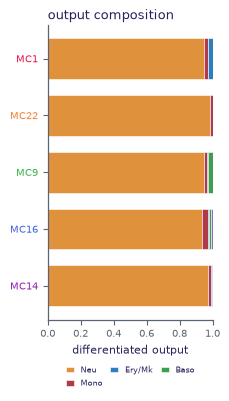

In [17]:
# --- Split plot 1/10: Neutrophil-primed output-composition bars ---
composition_panel("Neutrophil-primed","panel_2e_neu_composition")
print("saved panel_2e_neu_composition")


saved panel_2f_mono_composition


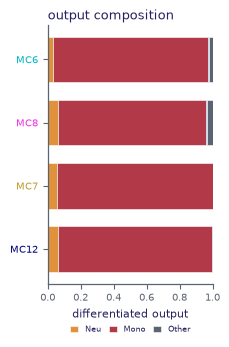

In [18]:
# --- Split plot 2/10: Monocyte-primed output-composition bars ---
composition_panel("Monocyte-primed","panel_2f_mono_composition")
print("saved panel_2f_mono_composition")


saved panel_2c_branch_Meg


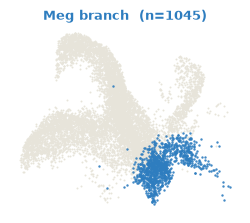

In [19]:
# --- Split plot 6/10: Meg branch UMAP ---
branch_umap_panel("Meg","panel_2c_branch_Meg")
print("saved panel_2c_branch_Meg")


saved panel_2c_branch_Mast


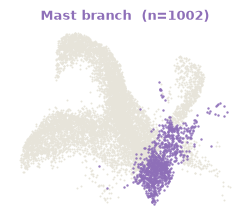

In [20]:
# --- Split plot 7/10: Mast branch UMAP ---
branch_umap_panel("Mast","panel_2c_branch_Mast")
print("saved panel_2c_branch_Mast")


saved panel_2c_branch_Baso


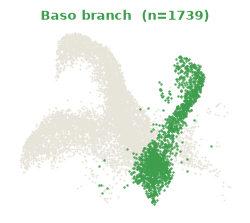

In [21]:
# --- Split plot 8/10: Baso branch UMAP ---
branch_umap_panel("Baso","panel_2c_branch_Baso")
print("saved panel_2c_branch_Baso")


saved panel_2c_branch_Neu


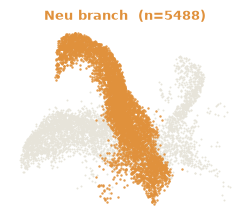

In [22]:
# --- Split plot 9/10: Neu branch UMAP ---
branch_umap_panel("Neu","panel_2c_branch_Neu")
print("saved panel_2c_branch_Neu")


saved panel_2c_branch_Mono


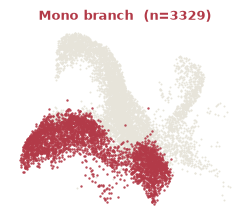

In [23]:
# --- Split plot 10/10: Mono branch UMAP ---
branch_umap_panel("Mono","panel_2c_branch_Mono")
print("saved panel_2c_branch_Mono")


In [24]:
# --- source data (no plot): pseudotime + branch masks used by the split trajectory panels ---
pd.DataFrame({"UMAP1":U[:,0],"UMAP2":U[:,1],"pseudotime":ptv,
              **{f"mask_{b}":obs[f"mask_{b}"].values for b in BRANCHES}},index=obs.index)\
  .to_csv(f"{DATADIR_S}/2c_pseudotime_masks.csv",index_label="cell")
print("saved 2c_pseudotime_masks.csv")


saved 2c_pseudotime_masks.csv


## 9. Panels f & g — gene analysis (metaclone-enabled)

The analysis asks two questions using trajectory-derived metaclone labels.

1. A myeloid-maturation program is defined from full-landscape Palantir pseudotime without using
   metaclone identity, then scored per cell and evaluated before and after conditioning on pseudotime.
2. Day-2 fast-versus-slow differential expression uses Mann-Whitney tests with BH-FDR, followed by a
   clone-aware cross-validated classifier in which whole clones are held out and clone labels are
   permuted for the null.

GO enrichment (gseapy/Enrichr, mouse GO:BP, expressed-gene background) is written to
`../Figure/fig2/gene_analysis/GO_*.csv`; gene counts and terms are reported from the tool, not narrated.
This is distinct from the research within-lineage DEG-count analysis (`analysis_workspace/figure2_weinreb`),
which was run on a 5000-HVG subset; here the full 25,289-gene transcriptome is used.

saved panels 2f, 2g


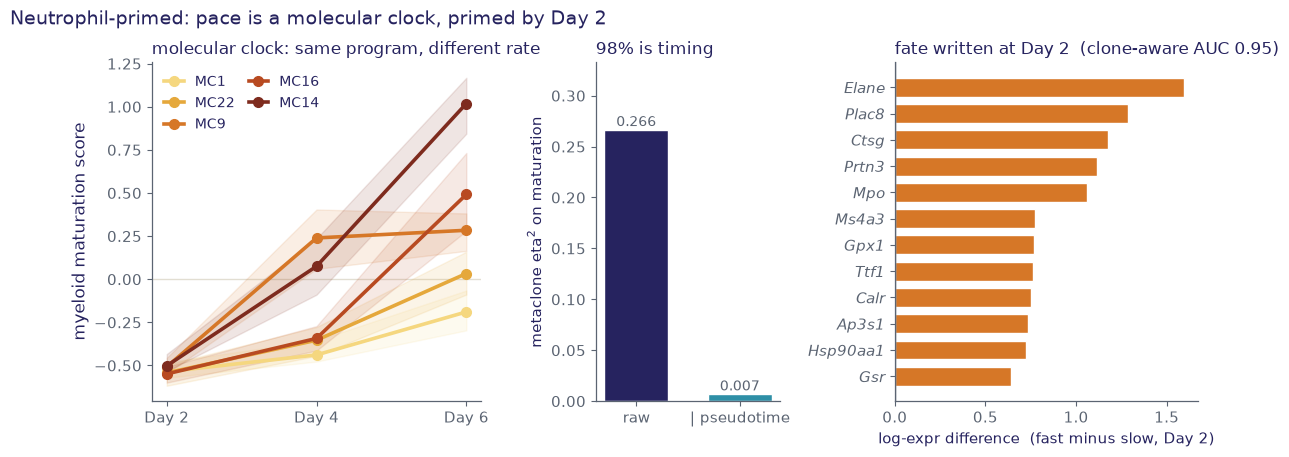

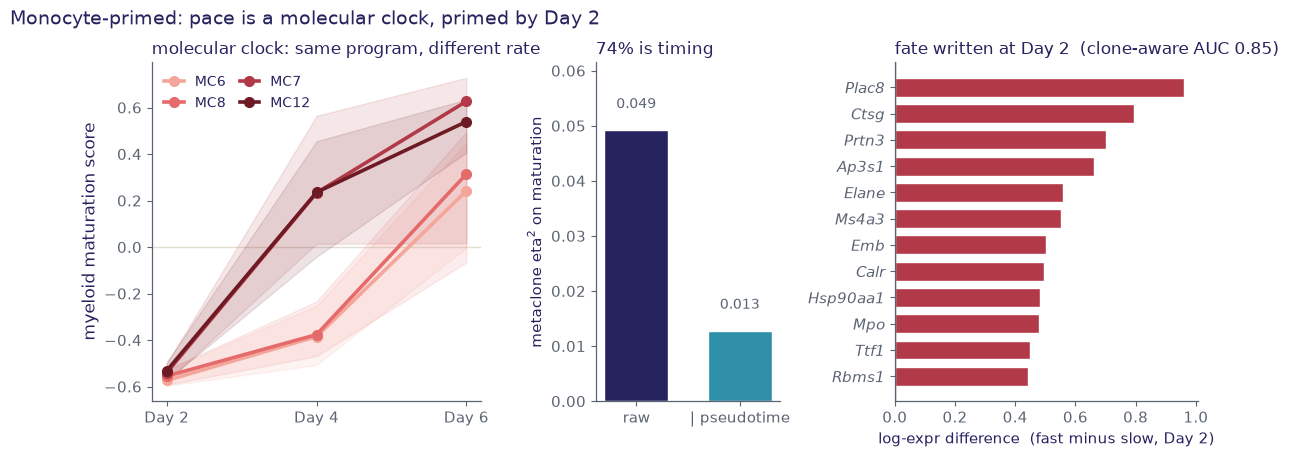

In [25]:
# ===== metaclone-enabled gene analysis: maturation clock + Day-2 priming =====
import scipy.sparse as sp
from scipy.stats import rankdata, norm, spearmanr
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
import matplotlib.gridspec as gridspec

X=A.X; genes=np.array(A.var.index)
keep=np.asarray((X>0).mean(0)).ravel()>0.05
Xk=X[:,keep]; gk=genes[keep]
Xdense=Xk.toarray() if sp.issparse(Xk) else np.asarray(Xk)
pt=obs["palantir_pseudotime"].values.astype(float); ok=np.isfinite(pt)

# --- maturation program: top pseudotime-correlated genes (NO metaclone info) ---
pr=rankdata(pt[ok]); prn=(pr-pr.mean())/np.linalg.norm(pr-pr.mean())
Xr=np.apply_along_axis(rankdata,0,Xdense[ok]); Xrc=Xr-Xr.mean(0)
rho=(Xrc/(np.linalg.norm(Xrc,axis=0)+1e-12)).T@prn
up=np.argsort(rho)[::-1][:100]; mat_genes=gk[up]
Msub=(Xdense[:,up]-Xdense[:,up].mean(0))/(Xdense[:,up].std(0)+1e-9)
obs2=obs.copy(); obs2["mat_score"]=Msub.mean(1); obs2["mc"]=pd.to_numeric(obs2["metaclone"],errors="coerce")

mc_all=pd.to_numeric(obs["metaclone"],errors="coerce").values; day_all=obs["day"].values
larry=obs["LARRY_ID"].astype(str).values
def cells(mcs,day=None):
    m=np.isin(mc_all,mcs); m=m&(day_all==day) if day is not None else m
    return np.where(m)[0]

def de_mannwhitney(ia,ib,mn=10):
    if len(ia)<mn or len(ib)<mn: return None
    A_=Xdense[ia]; B_=Xdense[ib]; na,nb=len(ia),len(ib)
    R=np.apply_along_axis(rankdata,0,np.vstack([A_,B_])); U=R[:na].sum(0)-na*(na+1)/2.0
    z=(U-na*nb/2.0)/np.sqrt(na*nb*(na+nb+1)/12.0); p=2*norm.sf(np.abs(z))
    return pd.DataFrame({"gene":gk,"auc":U/(na*nb),"lfc":A_.mean(0)-B_.mean(0),"p":p}).assign(
        fdr=lambda d: multipletests(d.p,method="fdr_bh")[1])

NEU=GROUPS["Neutrophil-primed"]["mcs"]; MONO=GROUPS["Monocyte-primed"]["mcs"]
NEU_fast,NEU_slow=[9,14],[1,22,16]; MONO_fast,MONO_slow=[7,12],[6,8]
res={"D2_NeuFast_vs_NeuSlow":de_mannwhitney(cells(NEU_fast,2),cells(NEU_slow,2)),
     "D2_MonoFast_vs_MonoSlow":de_mannwhitney(cells(MONO_fast,2),cells(MONO_slow,2)),
     "D2_Neu_vs_Mono":de_mannwhitney(cells(NEU,2),cells(MONO,2))}

def cv_auc_cloneaware(ia,ib,nperm=50,seed=0):
    idx=np.concatenate([ia,ib]); X_=Xdense[idx]; y=np.r_[np.ones(len(ia)),np.zeros(len(ib))]; grp=larry[idx]
    clf=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,C=0.5,class_weight="balanced"))
    ns=max(3,min(5,pd.Series(grp).nunique()//2,int(np.bincount(y.astype(int)).min())))
    cv=StratifiedGroupKFold(n_splits=ns,shuffle=True,random_state=seed)
    au=np.mean([roc_auc_score(y[te],clf.fit(X_[tr],y[tr]).predict_proba(X_[te])[:,1]) for tr,te in cv.split(X_,y,grp)])
    rng=np.random.default_rng(seed); cl2y=pd.Series(y,index=grp).groupby(level=0).first(); null=[]
    for _ in range(nperm):
        yp=pd.Series(rng.permutation(cl2y.values),index=cl2y.index).loc[grp].values
        a=[roc_auc_score(yp[te],clf.fit(X_[tr],yp[tr]).predict_proba(X_[te])[:,1])
           for tr,te in cv.split(X_,yp,grp) if len(np.unique(yp[tr]))>1]
        if a: null.append(np.mean(a))
    null=np.array(null); return au,(np.sum(null>=au)+1)/(len(null)+1)
CVAUC={"Neutrophil-primed":cv_auc_cloneaware(cells(NEU_fast,2),cells(NEU_slow,2)),
       "Monocyte-primed":cv_auc_cloneaware(cells(MONO_fast,2),cells(MONO_slow,2))}

def mc_clock(mcs):
    r=[]
    for m in mcs:
        for d in DAYS:
            v=obs2[(obs2.mc==m)&(obs2.day==d)]["mat_score"].values
            if len(v): r.append({"MC":m,"day":d,"med":np.median(v),"q1":np.percentile(v,25),"q3":np.percentile(v,75)})
    return pd.DataFrame(r)
def var_partition_vals(mcs):
    s=obs2[obs2.mc.isin(mcs)].dropna(subset=["mat_score","palantir_pseudotime"])
    def eta2(y,g):
        gm=y.mean(); return sum(len(y[g==k])*(y[g==k].mean()-gm)**2 for k in g.unique())/((y-gm)**2).sum()
    raw=eta2(s["mat_score"],s["mc"]); b=np.polyfit(s["palantir_pseudotime"],s["mat_score"],1)
    return raw,eta2(pd.Series(s["mat_score"].values-np.polyval(b,s["palantir_pseudotime"]),index=s.index),s["mc"])

def gene_panel(group_name,save_key,de_key,fast):
    mcs=GROUPS[group_name]["mcs"]; cmap=GROUPS[group_name]["cmap"]; mc2col=dict(zip(mcs,cmap)); clk=mc_clock(mcs); raw,resid=var_partition_vals(mcs)
    de=res[de_key]; de=de[de.fdr<0.05]; de=de.reindex(de["lfc"].abs().sort_values(ascending=False).index).head(12)
    fig=plt.figure(figsize=(13.5,4.4)); gs=gridspec.GridSpec(1,3,width_ratios=[1.25,0.7,1.15],wspace=0.42)
    ax=fig.add_subplot(gs[0])
    for m in mcs:
        c=clk[clk.MC==m].sort_values("day"); col=mc2col[m]
        ax.plot(c.day,c["med"],"-o",color=col,lw=2.6,ms=7,zorder=3,label=f"MC{m}")
        ax.fill_between(c.day,c.q1,c.q3,color=col,alpha=0.12,zorder=1)
    ax.set_xticks(DAYS); ax.set_xticklabels([f"Day {d}" for d in DAYS],fontsize=12)
    ax.set_ylabel("myeloid maturation score",fontsize=12)
    ax.set_title("molecular clock: same program, different rate",loc="left",fontsize=12.5,color=INK,pad=6)
    ax.axhline(0,color=HAIR,lw=1,zorder=0); ax.spines[["top","right"]].set_visible(False); ax.tick_params(labelsize=11)
    ax.legend(fontsize=10,frameon=False,ncol=2,loc="upper left",columnspacing=1.0,handlelength=1.4)
    ax2=fig.add_subplot(gs[1]); ax2.bar([0,1],[raw,resid],color=[INK,TEAL],width=0.62,edgecolor="white")
    ax2.set_xticks([0,1]); ax2.set_xticklabels(["raw","| pseudotime"],fontsize=11)
    ax2.set_ylabel("metaclone eta$^2$ on maturation",fontsize=11)
    ax2.set_title(f"{100*(1-resid/raw):.0f}% is timing",loc="left",fontsize=12.5,color=INK,pad=6)
    for i,v in enumerate([raw,resid]): ax2.text(i,v+0.004,f"{v:.3f}",ha="center",fontsize=10,color=GREY)
    ax2.set_ylim(0,max(raw,0.02)*1.25); ax2.spines[["top","right"]].set_visible(False); ax2.tick_params(labelsize=11)
    ax3=fig.add_subplot(gs[2]); de=de.sort_values("lfc"); y=np.arange(len(de))
    ax3.barh(y,de["lfc"],color=[mc2col[fast[0]] if v>0 else GREY for v in de["lfc"]],edgecolor="white",height=0.72)
    ax3.set_yticks(y); ax3.set_yticklabels(de["gene"],fontsize=10.5,style="italic"); ax3.axvline(0,color=GREY,lw=1)
    ax3.set_xlabel("log-expr difference  (fast minus slow, Day 2)",fontsize=11)
    au,_=CVAUC[group_name]
    ax3.set_title(f"fate written at Day 2  (clone-aware AUC {au:.2f})",loc="left",fontsize=12.5,color=INK,pad=6)
    ax3.spines[["top","right"]].set_visible(False); ax3.tick_params(labelsize=11)
    fig.suptitle(f"{group_name}: pace is a molecular clock, primed by Day 2",x=0.02,ha="left",fontsize=14,color=INK,y=1.0)
    fig.tight_layout(rect=[0,0,1,0.95])
    fig.savefig(f"{OUTDIR}/panel_{save_key}.svg",bbox_inches="tight")
    fig.savefig(f"{OUTDIR}/panel_{save_key}.pdf",dpi=300,bbox_inches="tight")
    fig.savefig(f"{OUTDIR}/panel_{save_key}.png",dpi=190,bbox_inches="tight")
    # source data
    clk.to_csv(f"{DATADIR}/fig2{save_key[1]}_maturation_clock.csv",index=False)
    res[de_key].sort_values("p").to_csv(f"{DATADIR}/fig2{save_key[1]}_day2_priming_DE.csv",index=False)
    return fig

_=gene_panel("Neutrophil-primed","2f_neu_genes","D2_NeuFast_vs_NeuSlow",NEU_fast)
_=gene_panel("Monocyte-primed","2g_mono_genes","D2_MonoFast_vs_MonoSlow",MONO_fast)
pd.DataFrame({"gene":mat_genes,"rho_pseudotime":np.round(rho[up],4)}).to_csv(f"{DATADIR}/fig2fg_maturation_program.csv",index=False)
print("saved panels 2f, 2g")

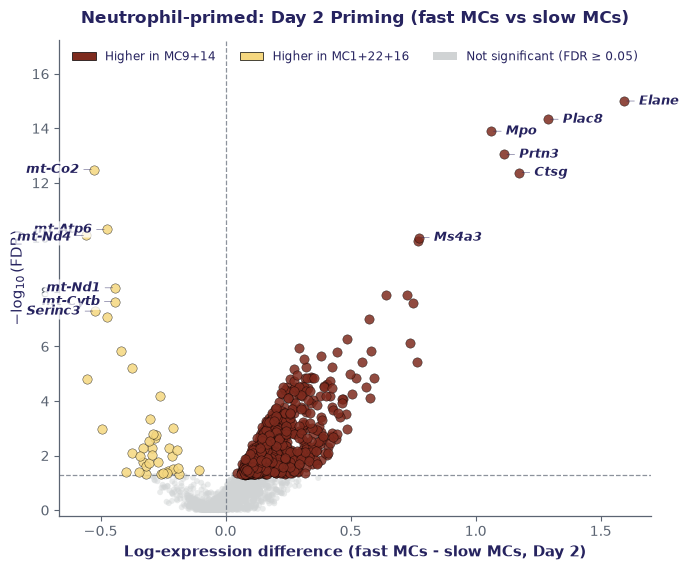

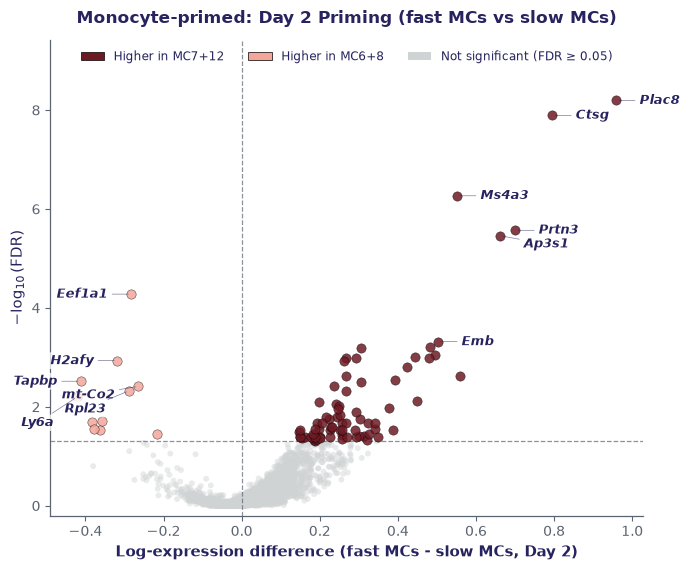

saved clean, non-overlapping volcano plots for 2f and 2g


In [26]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# -----------------------------------------------------------------------------
# Non-Overlapping Label Placement Helper
# -----------------------------------------------------------------------------
def place_labels_staggered(ax, df_sub, side="right"):
    """
    Vertically staggers gene labels to eliminate overlaps while connecting 
    each label to its target point with clean leader lines.
    """
    if len(df_sub) == 0: return
    
    df_sub = df_sub.sort_values("neg_log_fdr", ascending=False)
    y_vals = df_sub["neg_log_fdr"].values
    x_vals = df_sub["lfc"].values
    gene_names = df_sub["gene"].values
    
    n = len(df_sub)
    idx_order = np.argsort(y_vals)[::-1]
    
    # Enforce minimum vertical gap between labels
    min_gap = 0.28
    target_y = y_vals[idx_order].copy()
    
    for i in range(1, n):
        if target_y[i-1] - target_y[i] < min_gap:
            target_y[i] = target_y[i-1] - min_gap
            
    for i in range(n):
        orig_idx = idx_order[i]
        gx = x_vals[orig_idx]
        gy = y_vals[orig_idx]
        ty = target_y[i]
        gname = gene_names[orig_idx]
        
        tx = gx + (0.06 if side == "right" else -0.06)
        
        ax.annotate(
            gname,
            (gx, gy),
            xytext=(tx, ty),
            fontsize=9.0,
            fontweight="bold",
            fontstyle="italic",
            ha="left" if side == "right" else "right",
            va="center",
            arrowprops=dict(arrowstyle="-", color=INK, lw=0.5, alpha=0.6),
            bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.75)
        )

# -----------------------------------------------------------------------------
# Standalone Volcano Plot Generator
# -----------------------------------------------------------------------------
def volcano_panel_clean(group_name, de_key, save_key, fast_color, slow_color, fast_label, slow_label):
    df = res[de_key].copy()
    df["neg_log_fdr"] = -np.log10(np.maximum(df["fdr"], 1e-15))
    
    fig, ax = plt.subplots(figsize=(7.0, 5.8))
    
    # 1. Non-significant points (FDR >= 0.05)
    nonsig = df[df["fdr"] >= 0.05]
    ax.scatter(nonsig["lfc"], nonsig["neg_log_fdr"], c="#D0D3D4", s=18, alpha=0.45, edgecolors="none", rasterized=True)
    
    # 2. Significant Up in Fast (FDR < 0.05 & lfc > 0)
    fast_up = df[(df["fdr"] < 0.05) & (df["lfc"] > 0)]
    ax.scatter(fast_up["lfc"], fast_up["neg_log_fdr"], c=fast_color, s=45, alpha=0.85, edgecolors="black", linewidths=0.3, zorder=3)
    
    # 3. Significant Up in Slow (FDR < 0.05 & lfc < 0)
    slow_up = df[(df["fdr"] < 0.05) & (df["lfc"] < 0)]
    ax.scatter(slow_up["lfc"], slow_up["neg_log_fdr"], c=slow_color, s=45, alpha=0.85, edgecolors="black", linewidths=0.3, zorder=3)
    
    # 4. Significance threshold lines
    ax.axhline(-np.log10(0.05), color=GREY, linestyle="--", linewidth=0.9, alpha=0.7)
    ax.axvline(0, color=GREY, linestyle="--", linewidth=0.9, alpha=0.7)
    
    # 5. Non-overlapping gene annotations (top 6 per side)
    top_fast = fast_up.sort_values("fdr").head(6)
    top_slow = slow_up.sort_values("fdr").head(6)
    
    place_labels_staggered(ax, top_fast, side="right")
    place_labels_staggered(ax, top_slow, side="left")
        
    ax.set_xlabel(f"Log-expression difference (fast MCs - slow MCs, Day 2)", fontsize=11, fontweight="bold")
    ax.set_ylabel(r"$-\log_{10}(\text{FDR})$", fontsize=11, fontweight="bold")
    ax.set_title(f"{group_name}: Day 2 Priming (fast MCs vs slow MCs)", fontsize=12, fontweight="bold", pad=12, color=INK)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=10)
    
    # 6. Horizontal legend bar at upper center
    legend_handles = [
        Patch(facecolor=fast_color, edgecolor="black", lw=0.5, label=f"Higher in {fast_label}"),
        Patch(facecolor=slow_color, edgecolor="black", lw=0.5, label=f"Higher in {slow_label}"),
        Patch(facecolor="#D0D3D4", edgecolor="none", label="Not significant (FDR ≥ 0.05)")
    ]
    ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=8.5, ncol=3)
    
    # Upper y-axis headroom for title and legend
    ymax = max(df["neg_log_fdr"].max() * 1.15, 4.5)
    ax.set_ylim(-0.2, ymax)
    
    plt.tight_layout()
    fig.savefig(f"{OUTDIR}/panel_{save_key}.svg", bbox_inches="tight")
    fig.savefig(f"{OUTDIR}/panel_{save_key}.pdf", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUTDIR}/panel_{save_key}.png", dpi=600, bbox_inches="tight")
    plt.show()
    return fig

# -----------------------------------------------------------------------------
# Generate non-overlapping volcano plots
# -----------------------------------------------------------------------------
volcano_panel_clean("Neutrophil-primed", "D2_NeuFast_vs_NeuSlow", "2f_neu_volcano", "#7E2B1E", "#F5D77F", "MC9+14", "MC1+22+16")
volcano_panel_clean("Monocyte-primed", "D2_MonoFast_vs_MonoSlow", "2g_mono_volcano", "#6E1A24", "#F4A69A", "MC7+12", "MC6+8")

print("saved clean, non-overlapping volcano plots for 2f and 2g")

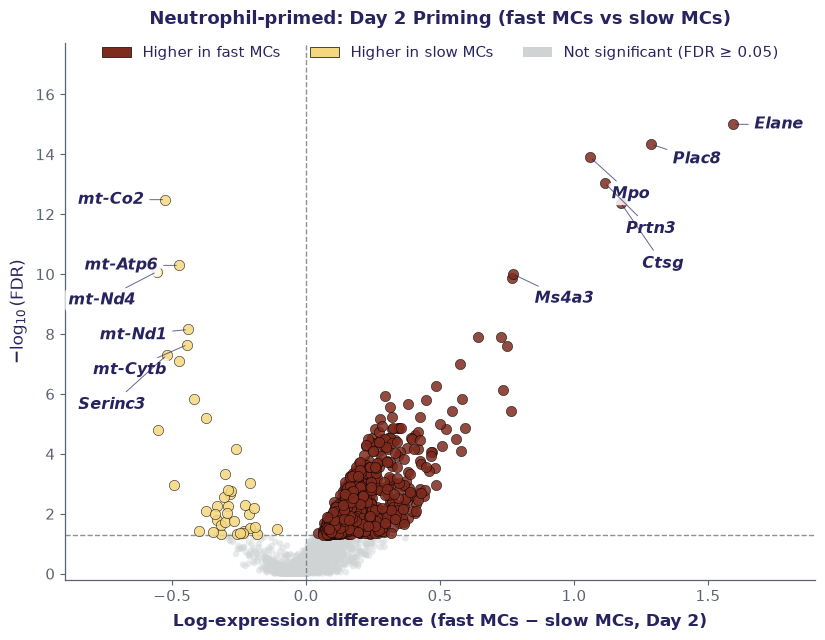

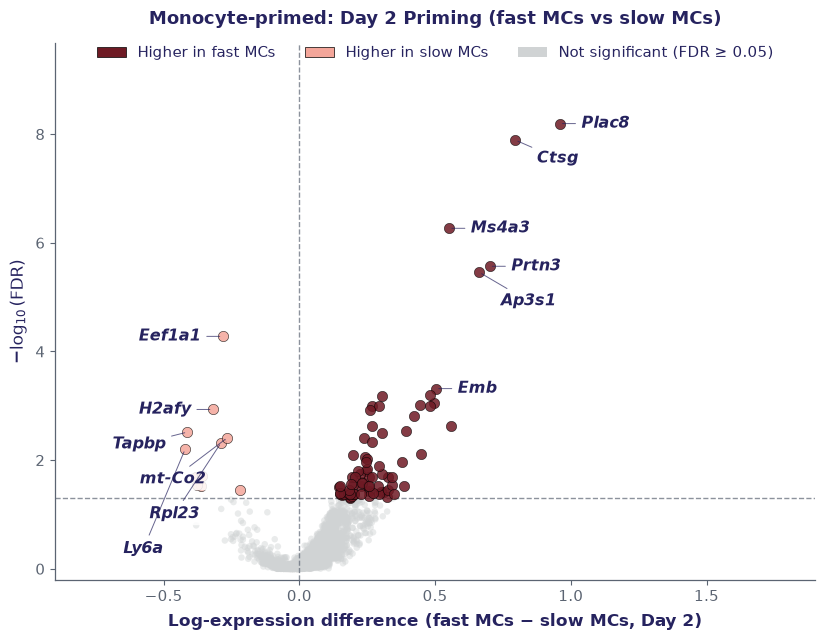

saved large-font clean volcano plots for 2f and 2g


In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# -----------------------------------------------------------------------------
# Large-Font Non-Overlapping Label Placement Helper
# -----------------------------------------------------------------------------
def place_labels_staggered_v2(ax, df_sub, y_range, side="right"):
    """
    Vertically staggers gene labels with 11.5pt bold text and dynamic spacing 
    scaled to the y-axis range to eliminate all text overlaps.
    """
    if len(df_sub) == 0: return
    
    df_sub = df_sub.sort_values("neg_log_fdr", ascending=False)
    y_vals = df_sub["neg_log_fdr"].values
    x_vals = df_sub["lfc"].values
    gene_names = df_sub["gene"].values
    
    n = len(df_sub)
    idx_order = np.argsort(y_vals)[::-1]
    
    # Dynamic min_gap scaling with y-axis range
    min_gap = max(0.065 * y_range, 0.6)
    target_y = y_vals[idx_order].copy()
    
    for i in range(1, n):
        if target_y[i-1] - target_y[i] < min_gap:
            target_y[i] = target_y[i-1] - min_gap
            
    for i in range(n):
        orig_idx = idx_order[i]
        gx = x_vals[orig_idx]
        gy = y_vals[orig_idx]
        ty = target_y[i]
        gname = gene_names[orig_idx]
        
        x_offset = 0.08 if side == "right" else -0.08
        tx = gx + x_offset
        
        ax.annotate(
            gname,
            (gx, gy),
            xytext=(tx, ty),
            fontsize=11.5,
            fontweight="bold",
            fontstyle="italic",
            ha="left" if side == "right" else "right",
            va="center",
            arrowprops=dict(arrowstyle="-", color=INK, lw=0.7, alpha=0.7),
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.85)
        )

# -----------------------------------------------------------------------------
# Standalone Volcano Plot Generator (Large Font & Dynamic Spacing)
# -----------------------------------------------------------------------------
def volcano_panel_clean_v2(group_name, de_key, save_key, fast_color, slow_color, fast_label, slow_label):
    df = res[de_key].copy()
    df["neg_log_fdr"] = -np.log10(np.maximum(df["fdr"], 1e-15))
    
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    
    # 1. Non-significant points (FDR >= 0.05)
    nonsig = df[df["fdr"] >= 0.05]
    ax.scatter(nonsig["lfc"], nonsig["neg_log_fdr"], c="#D0D3D4", s=22, alpha=0.45, edgecolors="none", rasterized=True)
    
    # 2. Significant Up in Fast Metaclone Group
    fast_up = df[(df["fdr"] < 0.05) & (df["lfc"] > 0)]
    ax.scatter(fast_up["lfc"], fast_up["neg_log_fdr"], c=fast_color, s=55, alpha=0.85, edgecolors="black", linewidths=0.4, zorder=3)
    
    # 3. Significant Up in Slow Metaclone Group
    slow_up = df[(df["fdr"] < 0.05) & (df["lfc"] < 0)]
    ax.scatter(slow_up["lfc"], slow_up["neg_log_fdr"], c=slow_color, s=55, alpha=0.85, edgecolors="black", linewidths=0.4, zorder=3)
    
    # 4. Significance threshold lines
    ax.axhline(-np.log10(0.05), color=GREY, linestyle="--", linewidth=1.0, alpha=0.7)
    ax.axvline(0, color=GREY, linestyle="--", linewidth=1.0, alpha=0.7)
    
    # 5. Calculate y-axis scale headroom
    ymax = max(df["neg_log_fdr"].max() * 1.18, 5.0)
    ax.set_ylim(-0.2, ymax)
    ax.set_xlim(-0.9, 1.9)
    y_range = ymax - (-0.2)
    
    # 6. Non-overlapping 11.5pt gene annotations (top 6 per side by FDR)
    top_fast = fast_up.sort_values("fdr").head(6)
    top_slow = slow_up.sort_values("fdr").head(6)
    
    place_labels_staggered_v2(ax, top_fast, y_range, side="right")
    place_labels_staggered_v2(ax, top_slow, y_range, side="left")
        
    # MODIFIED: Hardcoded "fast MCs" and "slow MCs" into x-axis and title
    ax.set_xlabel("Log-expression difference (fast MCs − slow MCs, Day 2)", fontsize=12, fontweight="bold", labelpad=6)
    ax.set_ylabel(r"$-\log_{10}(\text{FDR})$", fontsize=12, fontweight="bold", labelpad=6)
    ax.set_title(f"{group_name}: Day 2 Priming (fast MCs vs slow MCs)", fontsize=13, fontweight="bold", pad=14, color=INK)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=11)
    
    # 7. Horizontal legend bar at upper center
    # MODIFIED: Hardcoded "fast MCs" and "slow MCs" for the legend labels
    legend_handles = [
        Patch(facecolor=fast_color, edgecolor="black", lw=0.5, label="Higher in fast MCs"),
        Patch(facecolor=slow_color, edgecolor="black", lw=0.5, label="Higher in slow MCs"),
        Patch(facecolor="#D0D3D4", edgecolor="none", label="Not significant (FDR ≥ 0.05)")
    ]
    ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 1.02), frameon=False, fontsize=10.5, ncol=3)
    
    plt.tight_layout()
    
    # COMMENTED OUT: Saving functions and added today's date (_20260728) to the filenames
    fig.savefig(f"{OUTDIR}/panel_{save_key}_20260728.svg", bbox_inches="tight")
    fig.savefig(f"{OUTDIR}/panel_{save_key}_20260728.pdf", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUTDIR}/panel_{save_key}_20260728.png", dpi=600, bbox_inches="tight")
    
    plt.show() # Display inline for Jupyter Notebook
    return fig

# -----------------------------------------------------------------------------
# Generate volcano plots
# -----------------------------------------------------------------------------
volcano_panel_clean_v2("Neutrophil-primed", "D2_NeuFast_vs_NeuSlow", "2f_neu_volcano", "#7E2B1E", "#F5D77F", "MC9+14", "MC1+22+16")
volcano_panel_clean_v2("Monocyte-primed", "D2_MonoFast_vs_MonoSlow", "2g_mono_volcano", "#6E1A24", "#F4A69A", "MC7+12", "MC6+8")

print("saved large-font clean volcano plots for 2f and 2g")

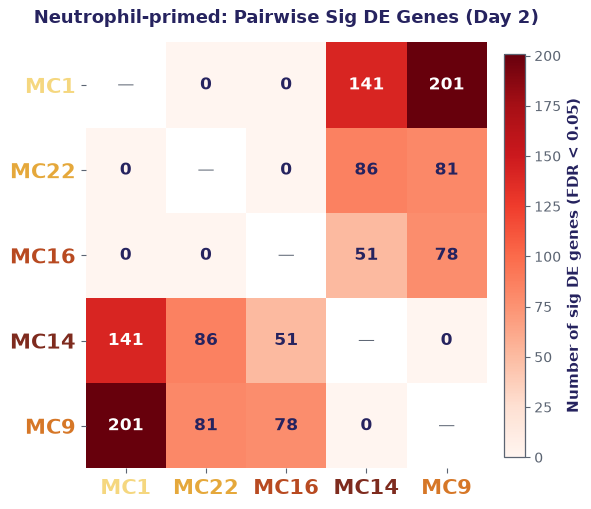

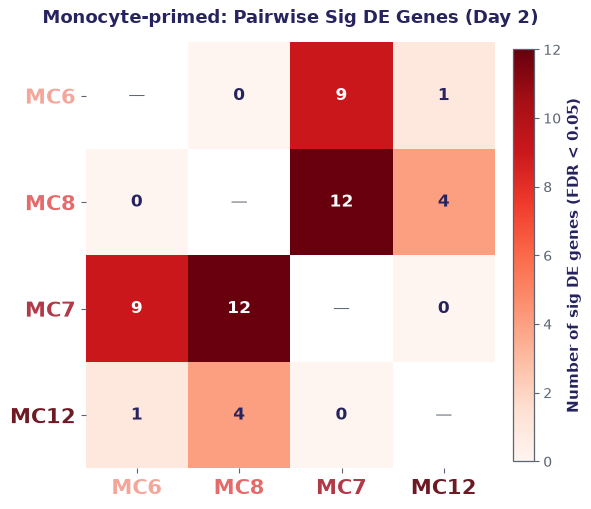

saved pairwise sig gene heatmaps with exact MC colors from legend images


In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import anndata as ad
import scipy.sparse as sp
from scipy.stats import rankdata, norm
from statsmodels.stats.multitest import multipletests

# -----------------------------------------------------------------------------
# Explicit Per-Metaclone Color Map matching Figure 2d/e Legend
# -----------------------------------------------------------------------------
MC_EXACT_COLOR = {
    # Neutrophil metaclones
    1:  "#F5D77F",  # Light cream yellow
    22: "#E5A83B",  # Golden amber
    9:  "#D67727",  # Deep orange
    16: "#B84A21",  # Burnt terracotta
    14: "#7E2B1E",  # Dark sienna
    
    # Monocyte metaclones
    6:  "#F4A69A",  # Soft coral / light pink
    8:  "#E56B6B",  # Coral red
    7:  "#B23A48",  # Crimson red
    12: "#6E1A24"   # Dark maroon
}

# -----------------------------------------------------------------------------
# Helper: Compute Pairwise DE Gene Count Matrix (Day 2)
# -----------------------------------------------------------------------------
def compute_pairwise_de_matrix(mcs, day=2, fdr_thresh=0.05):
    n = len(mcs)
    mat = np.zeros((n, n), dtype=int)
    
    for i in range(n):
        for j in range(n):
            if i != j:
                ia = cells(mcs[i], day)
                ib = cells(mcs[j], day)
                if len(ia) >= 5 and len(ib) >= 5:
                    A_ = Xdense[ia]; B_ = Xdense[ib]; na, nb = len(ia), len(ib)
                    R = np.apply_along_axis(rankdata, 0, np.vstack([A_, B_]))
                    U = R[:na].sum(0) - na * (na + 1) / 2.0
                    z = (U - na * nb / 2.0) / np.sqrt(na * nb * (na + nb + 1) / 12.0)
                    p = 2 * norm.sf(np.abs(z))
                    fdr = multipletests(p, method="fdr_bh")[1]
                    mat[i, j] = int((fdr < fdr_thresh).sum())
                    
    return pd.DataFrame(mat, index=[f"MC{m}" for m in mcs], columns=[f"MC{m}" for m in mcs])

# -----------------------------------------------------------------------------
# Helper: Render Heatmap with 15pt Bold Exact-Color MC Labels
# -----------------------------------------------------------------------------
def render_de_heatmap_exact_colors(df_mat, title_text, save_key, cmap_name="Reds"):
    fig, ax = plt.subplots(figsize=(6.0, 5.2))
    
    # Mask diagonal (self-comparison)
    mat_values = df_mat.values.astype(float)
    np.fill_diagonal(mat_values, np.nan)
    
    # Plot heatmap
    im = ax.imshow(mat_values, cmap=cmap_name, aspect="auto", origin="upper")
    
    # Annotate numeric counts in each cell
    n = len(df_mat)
    vmax = np.nanmax(mat_values) if np.nanmax(mat_values) > 0 else 1.0
    for i in range(n):
        for j in range(n):
            if i != j:
                val = int(df_mat.iloc[i, j])
                col = "white" if val > 0.5 * vmax else INK
                ax.text(j, i, f"{val}", ha="center", va="center", fontsize=12, fontweight="bold", color=col)
            else:
                ax.text(j, i, "—", ha="center", va="center", fontsize=12, color=GREY)
                
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    
    # Set 15pt bold tick labels
    ax.set_xticklabels(df_mat.columns, fontsize=15, fontweight="bold")
    ax.set_yticklabels(df_mat.index, fontsize=15, fontweight="bold")
    
    # Apply exact color matching per metaclone
    for label in ax.get_xticklabels():
        mc_num = int(label.get_text().replace("MC", ""))
        if mc_num in MC_EXACT_COLOR:
            label.set_color(MC_EXACT_COLOR[mc_num])
            label.set_fontsize(15)
            label.set_fontweight("bold")
            
    for label in ax.get_yticklabels():
        mc_num = int(label.get_text().replace("MC", ""))
        if mc_num in MC_EXACT_COLOR:
            label.set_color(MC_EXACT_COLOR[mc_num])
            label.set_fontsize(15)
            label.set_fontweight("bold")
            
    ax.set_title(title_text, fontsize=13, fontweight="bold", pad=14, color=INK)
    
    # Colorbar
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label("Number of sig DE genes (FDR < 0.05)", fontsize=10.5, fontweight="bold")
    cb.ax.tick_params(labelsize=10)
    
    for s in ax.spines.values():
        s.set_visible(False)
        
    plt.tight_layout()
    fig.savefig(f"{OUTDIR}/panel_{save_key}.svg", bbox_inches="tight")
    fig.savefig(f"{OUTDIR}/panel_{save_key}.pdf", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUTDIR}/panel_{save_key}.png", dpi=600, bbox_inches="tight")
    plt.show()
    return fig

# -----------------------------------------------------------------------------
# 1. Neutrophil-primed Heatmap (ordered: MC1, MC22, MC16, MC14, MC9)
# -----------------------------------------------------------------------------
neu_mcs = [1, 22, 16, 14, 9]
df_neu_de = compute_pairwise_de_matrix(neu_mcs, day=2)
render_de_heatmap_exact_colors(
    df_neu_de, 
    "Neutrophil-primed: Pairwise Sig DE Genes (Day 2)", 
    "2f_neu_de_heatmap", 
    cmap_name="Reds"
)

# -----------------------------------------------------------------------------
# 2. Monocyte-primed Heatmap (ordered: MC6, MC8, MC7, MC12)
# -----------------------------------------------------------------------------
mono_mcs = [6, 8, 7, 12]
df_mono_de = compute_pairwise_de_matrix(mono_mcs, day=2)
render_de_heatmap_exact_colors(
    df_mono_de, 
    "Monocyte-primed: Pairwise Sig DE Genes (Day 2)", 
    "2g_mono_de_heatmap", 
    cmap_name="Reds"
)

print("saved pairwise sig gene heatmaps with exact MC colors from legend images")

## 9b. Panel h — all metaclones grouped by lineage bias

A capstone survey placing the two pace groups (panels d/e) in the context of the
**full metaclone set**. Every metaclone is assigned to a lineage-bias family from its
own differentiated-output composition (dominant output >=60% -> that lineage;
otherwise **Multi-lineage**), then ordered within family by output purity. The right
column carries clone count, fraction of cells that are lineage-committed (`%diff`),
and the Day-6 pseudotime (pace). **Bold MC labels** are the strict-purity members
shown in the pace panels d/e.

saved panel 2h  |  families: {'Neutrophil': 5, 'Monocyte': 4, 'Erythroid / Mk': 3, 'Basophil': 1, 'Multi-lineage': 7}


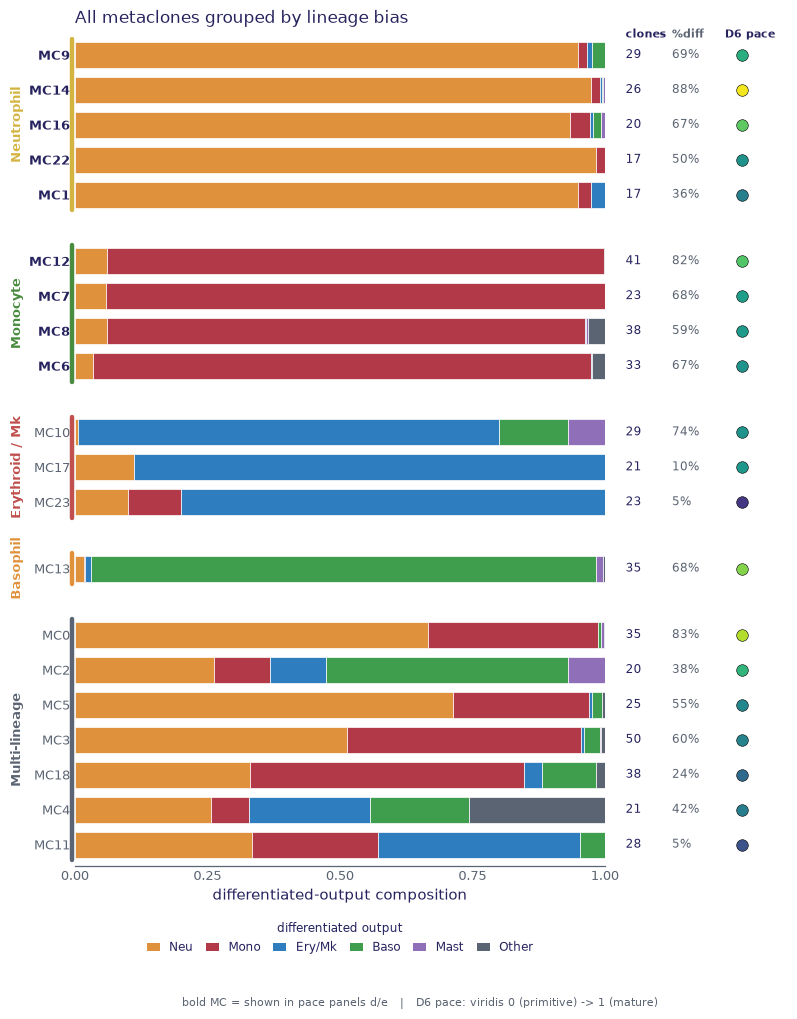

In [29]:
# ===== Panel h: all metaclones organised by lineage-bias family =====
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch

_prof = {m: output_profile([m]).iloc[0] for m in sorted(Cc["metaclone"].unique())}

CUSTOM_GROUPS_h = {
    "Neutrophil":     [9, 14, 16, 22, 1],
    "Monocyte":       [12, 7, 8, 6],
    "Erythroid / Mk": [10, 17, 23],
    "Basophil":       [13],
    "Multi-lineage":  [0, 2, 5, 3, 18, 4, 11]
}

_fam = {}
_order = []
for fam, mcs in CUSTOM_GROUPS_h.items():
    for m in mcs:
        if m in _prof:
            _fam[m] = fam
            _order.append(m)

MCS_ALL = list(_order)
FAM_ORDER  = ["Neutrophil","Monocyte","Erythroid / Mk","Basophil","Multi-lineage"]
FAM_ACCENT = {"Neutrophil":"#D4B441","Monocyte":"#4A8C3F","Erythroid / Mk":"#C0504D",
              "Basophil":AMBER,"Multi-lineage":GREY}
PACE  = set().union(*[set(d["mcs"]) for d in GROUPS.values()])

ys={}; y=0.0; prev=None
for m in _order:
    if prev is not None and _fam[m]!=prev: y-=0.9
    ys[m]=y; y-=1.0; prev=_fam[m]
ymin=min(ys.values())-0.6; ymax=0.6

fig=plt.figure(figsize=(9.2,0.42*len(MCS_ALL)+2.4))
gs=gridspec.GridSpec(1,2,width_ratios=[3.2,1.0],wspace=0.05)
axb=fig.add_subplot(gs[0]); axr=fig.add_subplot(gs[1],sharey=axb)

for m in MCS_ALL:
    left=0.0; p=_prof[m]
    for cat in OUT_ORDER:
        v=p[cat]
        if v>0: axb.barh(ys[m],v,left=left,height=0.74,color=OUT_COL[cat],edgecolor="white",lw=0.5)
        left+=v
axb.set_yticks([ys[m] for m in MCS_ALL])
axb.set_yticklabels([f"MC{m}" for m in MCS_ALL],fontsize=9)
for t,m in zip(axb.get_yticklabels(),MCS_ALL):
    if m in PACE: t.set_color(INK); t.set_fontweight("bold")
    else:         t.set_color(GREY)
axb.set_xlim(0,1); axb.set_ylim(ymin,ymax); axb.set_xticks([0,0.25,0.5,0.75,1.0])
axb.set_xlabel("differentiated-output composition",fontsize=10.5)
axb.set_title("All metaclones grouped by lineage bias",loc="left",fontsize=12.5,color=INK,pad=8)
axb.spines[["top","right","left"]].set_visible(False); axb.tick_params(length=0,labelsize=9)

# family accent bracket + rotated label at the left margin of each block
_famrows={}
for m in _order: _famrows.setdefault(_fam[m],[]).append(ys[m])
for f,yl in _famrows.items():
    ytop=max(yl)+0.45; ybot=min(yl)-0.45; ymid=(ytop+ybot)/2
    axb.add_line(plt.Line2D([-0.005,-0.005],[ybot,ytop],color=FAM_ACCENT[f],lw=3.2,clip_on=False,
                            transform=axb.get_yaxis_transform(),solid_capstyle="round"))
    axb.text(-0.11,ymid,f,rotation=90,va="center",ha="center",fontsize=9.5,color=FAM_ACCENT[f],
             fontweight="bold",transform=axb.get_yaxis_transform())

# right column: clones / %diff / D6-pace dot
recs=[]
for m in MCS_ALL:
    s=Cc[Cc["metaclone"]==m]; ncl=int(s["LARRY_ID"].nunique())
    fd=float((s["out"]!="undiff").mean()); ptd6=s[s["day"]==6]["pt"].median()
    axr.text(0.02,ys[m],f"{ncl:>2d}",fontsize=8.5,va="center",ha="left",fontfamily=UI,color=INK)
    axr.text(0.30,ys[m],f"{fd:.0%}",fontsize=8.5,va="center",ha="left",fontfamily=UI,color=GREY)
    if np.isfinite(ptd6):
        axr.scatter(0.72,ys[m],s=70,c=[ptd6],cmap="viridis",vmin=0,vmax=1,edgecolors="k",lw=0.4,zorder=3)
    recs.append(dict(metaclone=m,family=_fam[m],n_clones=ncl,frac_diff=round(fd,3),
                     pt_D6=round(float(ptd6),3) if np.isfinite(ptd6) else np.nan,
                     top_output=_prof[m].idxmax(),top_frac=round(float(_prof[m].max()),3),
                     in_pace_panel=(m in PACE),
                     **{f"out_{c}":round(float(_prof[m][c]),3) for c in OUT_ORDER}))
axr.set_xlim(0,1); axr.axis("off")
axr.text(0.02,ymax-0.1,"clones",fontsize=8,color=INK,fontweight="bold")
axr.text(0.30,ymax-0.1,"%diff", fontsize=8,color=GREY,fontweight="bold")
axr.text(0.62,ymax-0.1,"D6 pace",fontsize=8,color=INK,fontweight="bold")

hnd=[Patch(facecolor=OUT_COL[c],label=c) for c in OUT_ORDER]
axb.legend(handles=hnd,loc="upper center",bbox_to_anchor=(0.5,-0.055),ncol=6,frameon=False,
           fontsize=8.5,handlelength=1.1,columnspacing=1.1,title="differentiated output",title_fontsize=8.5)
fig.text(0.5,-0.02,"bold MC = shown in pace panels d/e   |   D6 pace: viridis 0 (primitive) -> 1 (mature)",
         ha="center",fontsize=8,color=GREY)
fig.tight_layout(rect=[0.02,0.02,1,0.98])
fig.savefig(f"{OUTDIR}/panel_2h_lineage_bias_map.pdf",dpi=300,bbox_inches="tight")
fig.savefig(f"{OUTDIR}/panel_2h_lineage_bias_map.png",dpi=170,bbox_inches="tight")
fig.savefig(f"{OUTDIR}/panel_2h_lineage_bias_map.svg",bbox_inches="tight")
pd.DataFrame(recs).to_csv(f"{DATADIR}/fig2h_lineage_bias_map.csv",index_label="cell")
print("saved panel 2h  |  families:", {f:sum(1 for m in MCS_ALL if _fam[m]==f) for f in FAM_ORDER})


## 9c. Panel i — clone-family density over time, all metaclones

The density-UMAP treatment of panel b extended to the **full metaclone set**. For each
metaclone and day, cells are coloured by local kNN purity (fraction of the 100 nearest
UMAP neighbours belonging to the same metaclone-day), so each clone family's occupied
territory and its migration across Day 2 -> 4 -> 6 is visible. Rows are ordered by the
same lineage-bias families as panel h (accent bars at left); **bold MC** = pace-panel
member (d/e). Density is scaled per metaclone (`n` under each map).

[Panel i environment] conda/chronoclone |  ~/micromamba/envs/chronoclone/bin/python
[Panel i versions] Python 3.11.15 | anndata 0.12.19 | numpy 2.4.6 | pandas 2.3.3 | matplotlib 3.11.0 | scikit-learn 1.9.0
        family  first_mc  last_mc
    Neutrophil        22        0
      Monocyte         7        8
Erythroid / Mk        17       10
      Basophil        13       13
 Multi-lineage        18        4
saved panel 2i  | 20 metaclones x 3 days | family bars aligned after layout


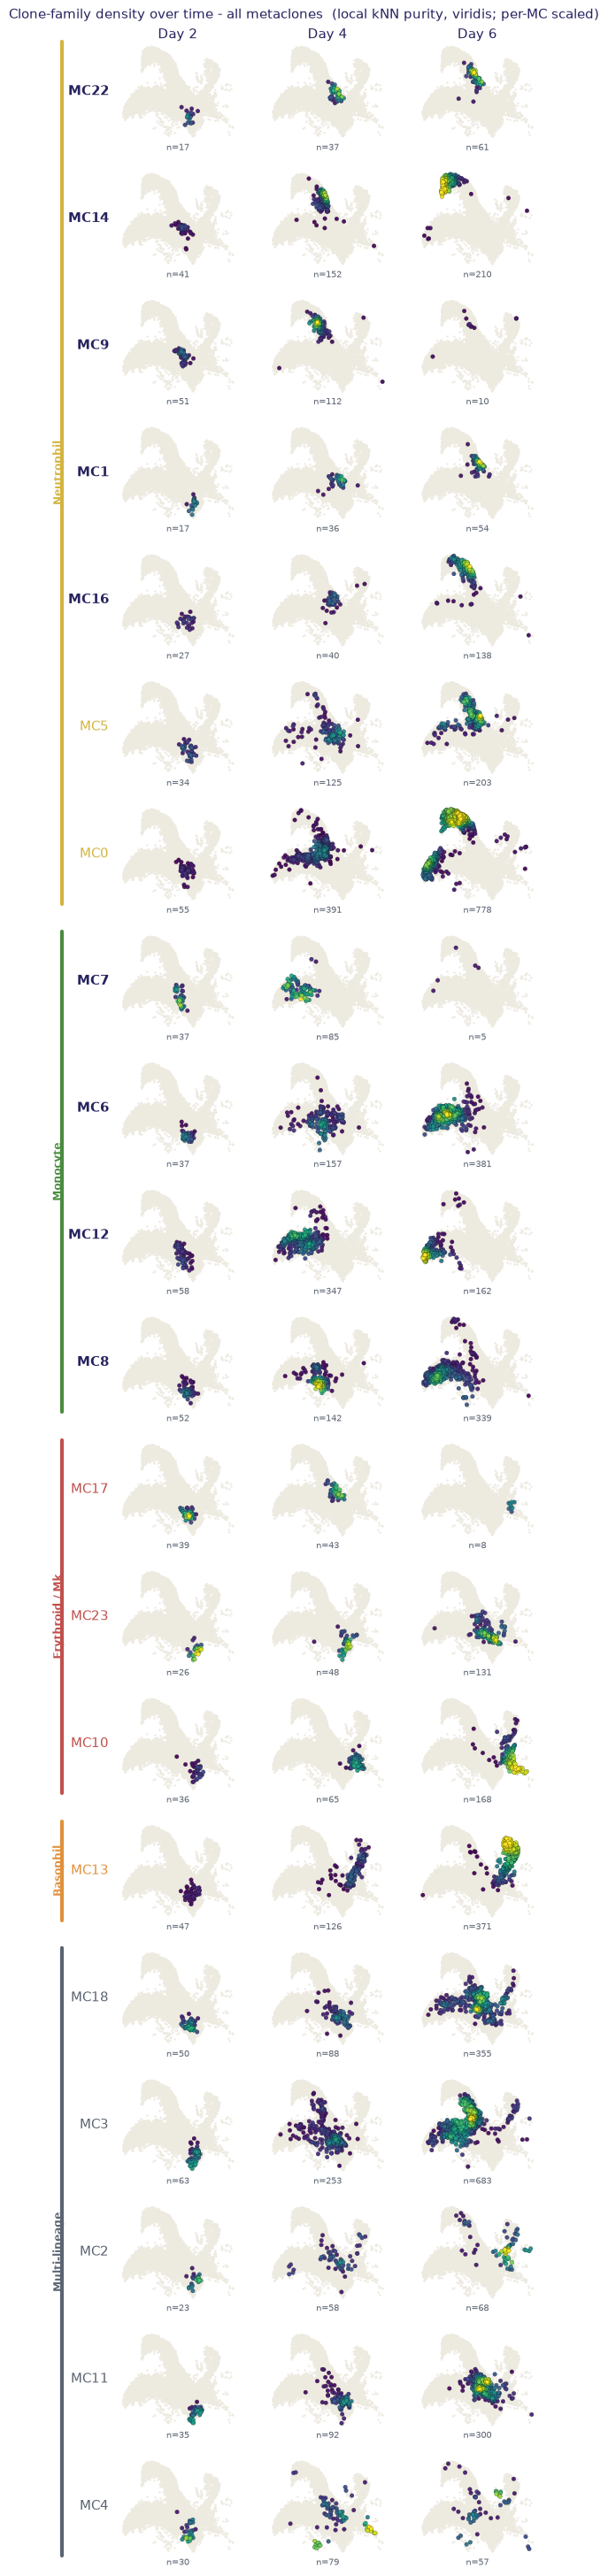

In [30]:
# ===== Panel i: clone-family density over time for every metaclone =====
# reuse the kNN-purity machinery + family classification from panels b and h
# Material-update provenance (2026-07-27): existing environment reused, not modified.
# manager/name: conda / chronoclone
# MacBook path: /path/to/ChronoClone/.runtime/chronoclone
# kernel: chronoclone | Python 3.11.15
# execution command: cd /path/to/ChronoClone/reference_workspace/notebooks && \
#   /path/to/ChronoClone/.runtime/chronoclone/bin/jupyter nbconvert \
#   --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone \
#   Figure2_klein_pace.ipynb
import sys, importlib.metadata as _im_i
print("[Panel i environment] conda/chronoclone | ", sys.executable)
print("[Panel i versions] Python", sys.version.split()[0], "| anndata", _im_i.version("anndata"),
      "| numpy", _im_i.version("numpy"), "| pandas", _im_i.version("pandas"),
      "| matplotlib", _im_i.version("matplotlib"), "| scikit-learn", _im_i.version("scikit-learn"))
_prof_i = {m: output_profile([m]).iloc[0] for m in sorted(Cc["metaclone"].unique())}
MCS_ALL_i = sorted(_prof_i.keys())
def _classify_i(m):
    p=_prof_i[m]
    if p.max()<0.60: return "Multi-lineage"
    return {"Neu":"Neutrophil","Mono":"Monocyte","Ery/Mk":"Erythroid / Mk",
            "Baso":"Basophil","Mast":"Mast","Other":"Other"}[p.idxmax()]
FAM_ORDER_i  = ["Neutrophil","Monocyte","Erythroid / Mk","Basophil","Multi-lineage"]
FAM_ACCENT_i = {"Neutrophil":"#D4B441","Monocyte":"#4A8C3F","Erythroid / Mk":"#C0504D",
                "Basophil":AMBER,"Multi-lineage":GREY}
_fam_i = {m:_classify_i(m) for m in MCS_ALL_i}
_order_i = sorted(MCS_ALL_i, key=lambda m:(FAM_ORDER_i.index(_fam_i[m]), -_prof_i[m].max()))
PACE_i = set().union(*[set(d["mcs"]) for d in GROUPS.values()])

_vmax_i={}
for m in MCS_ALL_i:
    vs=[purity_density(m,dd)[1] for dd in DAYS]
    _vmax_i[m]=max(max([(v.max() if v is not None and len(v) else 0) for v in vs]),5)

_xmn,_xmx=U[:,0].min()-1,U[:,0].max()+1; _ymn,_ymx=U[:,1].min()-1,U[:,1].max()+1
_nr=len(_order_i)
fig,axes=plt.subplots(_nr,3,figsize=(5.6,1.45*_nr))
for r,m in enumerate(_order_i):
    fcol=FAM_ACCENT_i[_fam_i[m]]; vmax=_vmax_i[m]
    for c,day in enumerate(DAYS):
        ax=axes[r,c]
        ax.scatter(U[:,0],U[:,1],s=3,c="#EDEAE0",lw=0,rasterized=True,zorder=0)
        coords,dens,idx=purity_density(m,day); n=0
        if coords is not None:
            o=dens.argsort()
            ax.scatter(coords[o,0],coords[o,1],c=dens[o],cmap="viridis",s=11,alpha=0.95,
                       edgecolors="black",linewidths=0.15,vmin=0,vmax=vmax,rasterized=True,zorder=2)
            n=len(idx)
        ax.set_aspect("equal"); ax.set_xlim(_xmn,_xmx); ax.set_ylim(_ymn,_ymx); ax.axis("off")
        if r==0: ax.set_title(f"Day {day}",fontsize=11,color=INK,pad=3)
        if c==0:
            ax.text(-0.08,0.5,f"MC{m}",transform=ax.transAxes,fontsize=10.5,
                    color=(INK if m in PACE_i else fcol),
                    fontweight=("bold" if m in PACE_i else "normal"),ha="right",va="center")
        ax.text(0.5,-0.02,f"n={n}",transform=ax.transAxes,fontsize=7.5,color=GREY,ha="center",va="top")
# Finalise the subplot geometry BEFORE measuring axes positions for the family bars.
# Measuring first and adjusting afterwards shifts every bar away from its row block.
fig.suptitle("Clone-family density over time - all metaclones  (local kNN purity, viridis; per-MC scaled)",
             x=0.5,y=0.998,fontsize=10.5,color=INK)
fig.subplots_adjust(left=0.10,right=0.995,top=0.985,bottom=0.005,hspace=0.28,wspace=0.04)
fig.canvas.draw()
_famrows={}
for r,m in enumerate(_order_i): _famrows.setdefault(_fam_i[m],[]).append(r)
_bar_alignment_i=[]
for f,rr in _famrows.items():
    top=axes[min(rr),0].get_position().y1; bot=axes[max(rr),0].get_position().y0
    fig.add_artist(plt.Line2D([0.012,0.012],[bot,top],color=FAM_ACCENT_i[f],lw=3.0,
                   solid_capstyle="round",transform=fig.transFigure))
    fig.text(0.004,(top+bot)/2,f,rotation=90,fontsize=8.5,color=FAM_ACCENT_i[f],
             fontweight="bold",ha="center",va="center")
    _bar_alignment_i.append(dict(family=f, first_row=min(rr), last_row=max(rr),
                                 first_mc=int(_order_i[min(rr)]), last_mc=int(_order_i[max(rr)]),
                                 bar_top=top, bar_bottom=bot,
                                 axes_top=axes[min(rr),0].get_position().y1,
                                 axes_bottom=axes[max(rr),0].get_position().y0))
_bar_alignment_i=pd.DataFrame(_bar_alignment_i)
assert np.allclose(_bar_alignment_i["bar_top"],_bar_alignment_i["axes_top"])
assert np.allclose(_bar_alignment_i["bar_bottom"],_bar_alignment_i["axes_bottom"])
fig.savefig(f"{OUTDIR}/panel_2i_density_all_mc.pdf",dpi=300,bbox_inches="tight")
fig.savefig(f"{OUTDIR}/panel_2i_density_all_mc.png",dpi=150,bbox_inches="tight")
fig.savefig(f"{OUTDIR}/panel_2i_density_all_mc.svg",bbox_inches="tight")
print(_bar_alignment_i[["family","first_mc","last_mc"]].to_string(index=False))
print("saved panel 2i  |", _nr, "metaclones x 3 days | family bars aligned after layout")

saved panel 2h | all labels bold, D6 pace & footnote removed


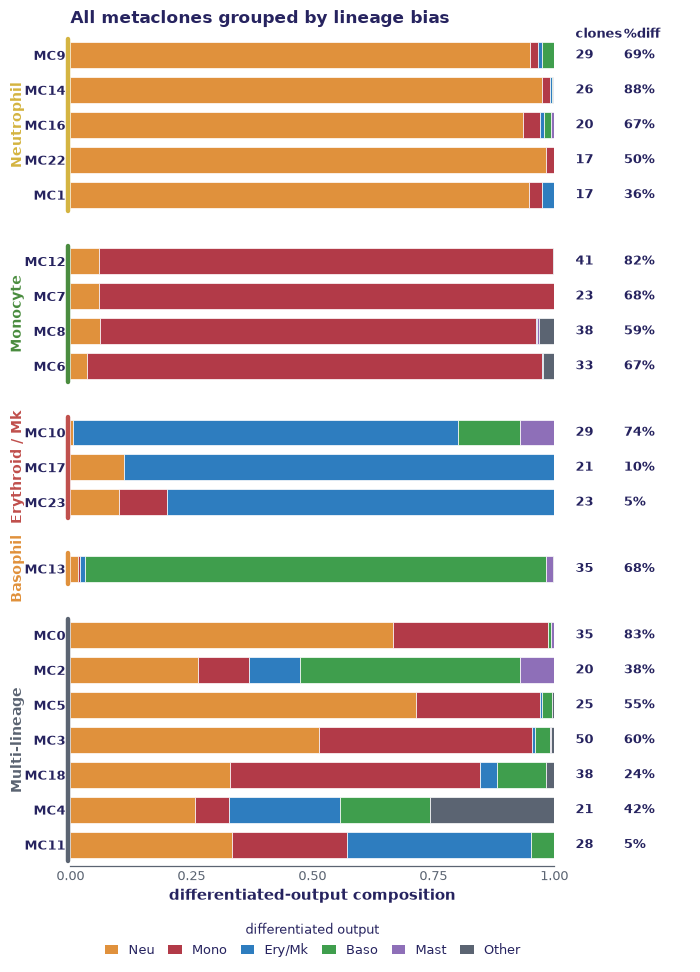

In [31]:
# ===== Panel h: all metaclones organised by lineage-bias family =====
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch

_prof = {m: output_profile([m]).iloc[0] for m in sorted(Cc["metaclone"].unique())}

CUSTOM_GROUPS_h = {
    "Neutrophil":     [9, 14, 16, 22, 1],
    "Monocyte":       [12, 7, 8, 6],
    "Erythroid / Mk": [10, 17, 23],
    "Basophil":       [13],
    "Multi-lineage":  [0, 2, 5, 3, 18, 4, 11]
}

_fam = {}
_order = []
for fam, mcs in CUSTOM_GROUPS_h.items():
    for m in mcs:
        if m in _prof:
            _fam[m] = fam
            _order.append(m)

MCS_ALL = list(_order)
FAM_ORDER  = ["Neutrophil","Monocyte","Erythroid / Mk","Basophil","Multi-lineage"]
FAM_ACCENT = {"Neutrophil":"#D4B441","Monocyte":"#4A8C3F","Erythroid / Mk":"#C0504D",
              "Basophil":AMBER,"Multi-lineage":GREY}

ys={}; y=0.0; prev=None
for m in _order:
    if prev is not None and _fam[m]!=prev: y-=0.9
    ys[m]=y; y-=1.0; prev=_fam[m]
ymin=min(ys.values())-0.6; ymax=0.6

fig=plt.figure(figsize=(8.0,0.42*len(MCS_ALL)+2.4))
gs=gridspec.GridSpec(1,2,width_ratios=[3.2,0.8],wspace=0.05)
axb=fig.add_subplot(gs[0]); axr=fig.add_subplot(gs[1],sharey=axb)

for m in MCS_ALL:
    left=0.0; p=_prof[m]
    for cat in OUT_ORDER:
        v=p[cat]
        if v>0: axb.barh(ys[m],v,left=left,height=0.74,color=OUT_COL[cat],edgecolor="white",lw=0.5)
        left+=v
axb.set_yticks([ys[m] for m in MCS_ALL])
axb.set_yticklabels([f"MC{m}" for m in MCS_ALL],fontsize=9.5,fontweight="bold")
for t in axb.get_yticklabels():
    t.set_color(INK)
axb.set_xlim(0,1); axb.set_ylim(ymin,ymax); axb.set_xticks([0,0.25,0.5,0.75,1.0])
axb.set_xlabel("differentiated-output composition",fontsize=10.5,fontweight="bold")
axb.set_title("All metaclones grouped by lineage bias",loc="left",fontsize=12.5,color=INK,pad=8,fontweight="bold")
axb.spines[["top","right","left"]].set_visible(False); axb.tick_params(length=0,labelsize=9)

# family accent bracket + rotated label at the left margin of each block
_famrows={}
for m in _order: _famrows.setdefault(_fam[m],[]).append(ys[m])
for f,yl in _famrows.items():
    ytop=max(yl)+0.45; ybot=min(yl)-0.45; ymid=(ytop+ybot)/2
    axb.add_line(plt.Line2D([-0.005,-0.005],[ybot,ytop],color=FAM_ACCENT[f],lw=3.2,clip_on=False,
                            transform=axb.get_yaxis_transform(),solid_capstyle="round"))
    axb.text(-0.11,ymid,f,rotation=90,va="center",ha="center",fontsize=10,color=FAM_ACCENT[f],
             fontweight="bold",transform=axb.get_yaxis_transform())

# right column: clones / %diff
recs=[]
for m in MCS_ALL:
    s=Cc[Cc["metaclone"]==m]; ncl=int(s["LARRY_ID"].nunique())
    fd=float((s["out"]!="undiff").mean()); ptd6=s[s["day"]==6]["pt"].median()
    axr.text(0.05,ys[m],f"{ncl:>2d}",fontsize=9,va="center",ha="left",fontfamily=UI,color=INK,fontweight="bold")
    axr.text(0.45,ys[m],f"{fd:.0%}",fontsize=9,va="center",ha="left",fontfamily=UI,color=INK,fontweight="bold")
    recs.append(dict(metaclone=m,family=_fam[m],n_clones=ncl,frac_diff=round(fd,3),
                     pt_D6=round(float(ptd6),3) if np.isfinite(ptd6) else np.nan,
                     top_output=_prof[m].idxmax(),top_frac=round(float(_prof[m].max()),3),
                     **{f"out_{c}":round(float(_prof[m][c]),3) for c in OUT_ORDER}))
axr.set_xlim(0,1); axr.axis("off")
axr.text(0.05,ymax-0.1,"clones",fontsize=9,color=INK,fontweight="bold")
axr.text(0.45,ymax-0.1,"%diff", fontsize=9,color=INK,fontweight="bold")

hnd=[Patch(facecolor=OUT_COL[c],label=c) for c in OUT_ORDER]
axb.legend(handles=hnd,loc="upper center",bbox_to_anchor=(0.5,-0.055),ncol=6,frameon=False,
           fontsize=9,handlelength=1.1,columnspacing=1.1,title="differentiated output",title_fontsize=9)
fig.tight_layout(rect=[0.02,0.02,1,0.98])
fig.savefig(f"{OUTDIR}/panel_2h_lineage_bias_map.pdf",dpi=300,bbox_inches="tight")
fig.savefig(f"{OUTDIR}/panel_2h_lineage_bias_map.png",dpi=170,bbox_inches="tight")
fig.savefig(f"{OUTDIR}/panel_2h_lineage_bias_map.svg",bbox_inches="tight")
pd.DataFrame(recs).to_csv(f"{DATADIR}/fig2h_lineage_bias_map.csv",index_label="cell")
print("saved panel 2h | all labels bold, D6 pace & footnote removed")


saved panel 2i (wider overall, increased spacing between lineage label & color bar)


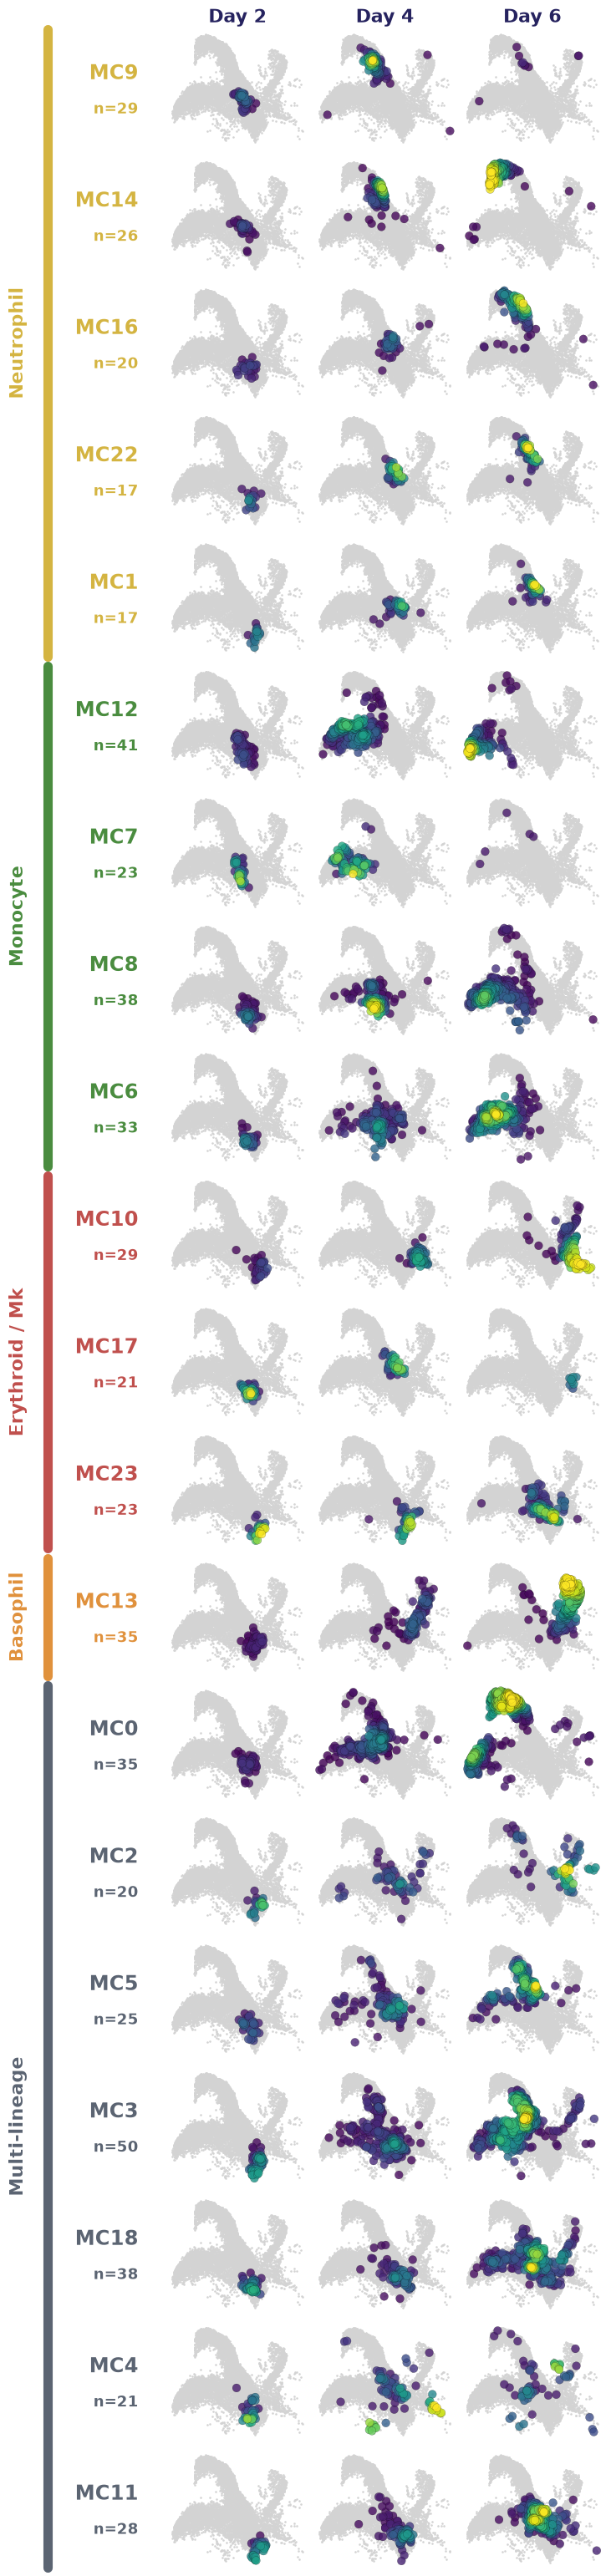

In [32]:
# ===== Panel i: clone-family density over time for every metaclone =====
# reuse the kNN-purity machinery + family classification from panels b and h

import sys, importlib.metadata as _im_i
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.lines as mlines
import numpy as np
import pandas as pd

# -------------------------------------------------------------------------
# User Controls: Metaclones to exclude and explicit custom ordering/grouping
EXCLUDE_MCS = []  # e.g., EXCLUDE_MCS = [1, 2] or leave empty []

# Custom order specified by user:
CUSTOM_GROUPS_i = {
    "Neutrophil":     [9, 14, 16, 22, 1],
    "Monocyte":       [12, 7, 8, 6],
    "Erythroid / Mk": [10, 17, 23],
    "Basophil":       [13],
    "Multi-lineage":  [0, 2, 5, 3, 18, 4, 11]
}
# -------------------------------------------------------------------------

# Map family name for each metaclone and construct full ordered list
_fam_i = {}
_order_i = []
for fam, mcs in CUSTOM_GROUPS_i.items():
    for m in mcs:
        if m not in EXCLUDE_MCS:
            _fam_i[m] = fam
            _order_i.append(m)

FAM_ACCENT_i = {"Neutrophil": "#D4B441", "Monocyte": "#4A8C3F", "Erythroid / Mk": "#C0504D",
                "Basophil": AMBER, "Multi-lineage": GREY}

_vmax_i = {}
for m in _order_i:
    vs = [purity_density(m, dd)[1] for dd in DAYS]
    _vmax_i[m] = max(max([(v.max() if v is not None and len(v) else 0) for v in vs]), 5)

_xmn, _xmx = U[:, 0].min() - 1, U[:, 0].max() + 1
_ymn, _ymx = U[:, 1].min() - 1, U[:, 1].max() + 1
_nr = len(_order_i)

# Create grid: 3 UMAP columns (Wider figure dimensions)
fig = plt.figure(figsize=(7.2, 1.55 * _nr))
gs = gridspec.GridSpec(_nr, 3, figure=fig, wspace=0.02, hspace=0.08)

for r, m in enumerate(_order_i):
    fcol = FAM_ACCENT_i[_fam_i[m]]
    vmax = _vmax_i[m]

    # Count unique clone barcodes (LARRY_ID) for metaclone m
    n_clones = int(Cc[Cc["metaclone"] == m]["LARRY_ID"].nunique())

    for c, day in enumerate(DAYS):
        ax = fig.add_subplot(gs[r, c])
        ax.scatter(U[:, 0], U[:, 1], s=3.5, c="lightgrey", lw=0, rasterized=True, zorder=0)
        coords, dens, idx = purity_density(m, day)
        if coords is not None:
            o = dens.argsort()
            ax.scatter(coords[o, 0], coords[o, 1], c=dens[o], cmap="viridis", s=50, alpha=0.8,
                       edgecolors="black", linewidths=0.15, vmin=0, vmax=vmax, rasterized=True, zorder=2)
            
        ax.set_aspect("equal")
        ax.set_xlim(_xmn, _xmx)
        ax.set_ylim(_ymn, _ymx)
        ax.axis("off")
        
        if r == 0:
            ax.set_title(f"Day {day}", fontsize=16, color=INK, pad=6, fontweight="bold")
            
        if c == 0:
            # Metaclone label (bold, matching group color)
            ax.text(-0.20, 0.62, f"MC{m}", transform=ax.transAxes, fontsize=17,
                    color=fcol, fontweight="bold", ha="right", va="center")
            # Unique clone barcode count (bold, matching group color)
            ax.text(-0.20, 0.32, f"n={n_clones}", transform=ax.transAxes, fontsize=13,
                    color=fcol, fontweight="bold", ha="right", va="center")

# Adjust figure margin (wider left to fit spaced lineage labels + color bar + MC text)
fig.subplots_adjust(left=0.26, right=0.99, top=0.985, bottom=0.005)
fig.canvas.draw()

# Family group bars on the left (spaced lineage label vs color bar)
_famrows = {}
for r, m in enumerate(_order_i):
    _famrows.setdefault(_fam_i[m], []).append(r)

_bar_alignment_i = []
for f, rr in _famrows.items():
    top = fig.axes[min(rr)*3].get_position().y1
    bot = fig.axes[max(rr)*3].get_position().y0
    # Thicker color block (lw=8), placed closer to MC labels at x=0.065
    fig.add_artist(plt.Line2D([0.065, 0.065], [bot, top], color=FAM_ACCENT_i[f], lw=8,
                              solid_capstyle="round", transform=fig.transFigure))
    # Lineage label spaced further left at x=0.015
    fig.text(0.015, (top + bot) / 2, f, rotation=90, fontsize=16, color=FAM_ACCENT_i[f],
             fontweight="bold", ha="center", va="center")

# Construct output tag based on exclusions
tag = f"_excl_{'_'.join(map(str, EXCLUDE_MCS))}" if EXCLUDE_MCS else ""

fig.savefig(f"{OUTDIR}/panel_2i_density_all_mc{tag}.pdf", dpi=300, bbox_inches="tight")
fig.savefig(f"{OUTDIR}/panel_2i_density_all_mc{tag}.png", dpi=600, bbox_inches="tight")
fig.savefig(f"{OUTDIR}/panel_2i_density_all_mc{tag}.svg", bbox_inches="tight")

print(f"saved panel 2i (wider overall, increased spacing between lineage label & color bar)")

saved panel 2i flipped (3 rows × N columns)


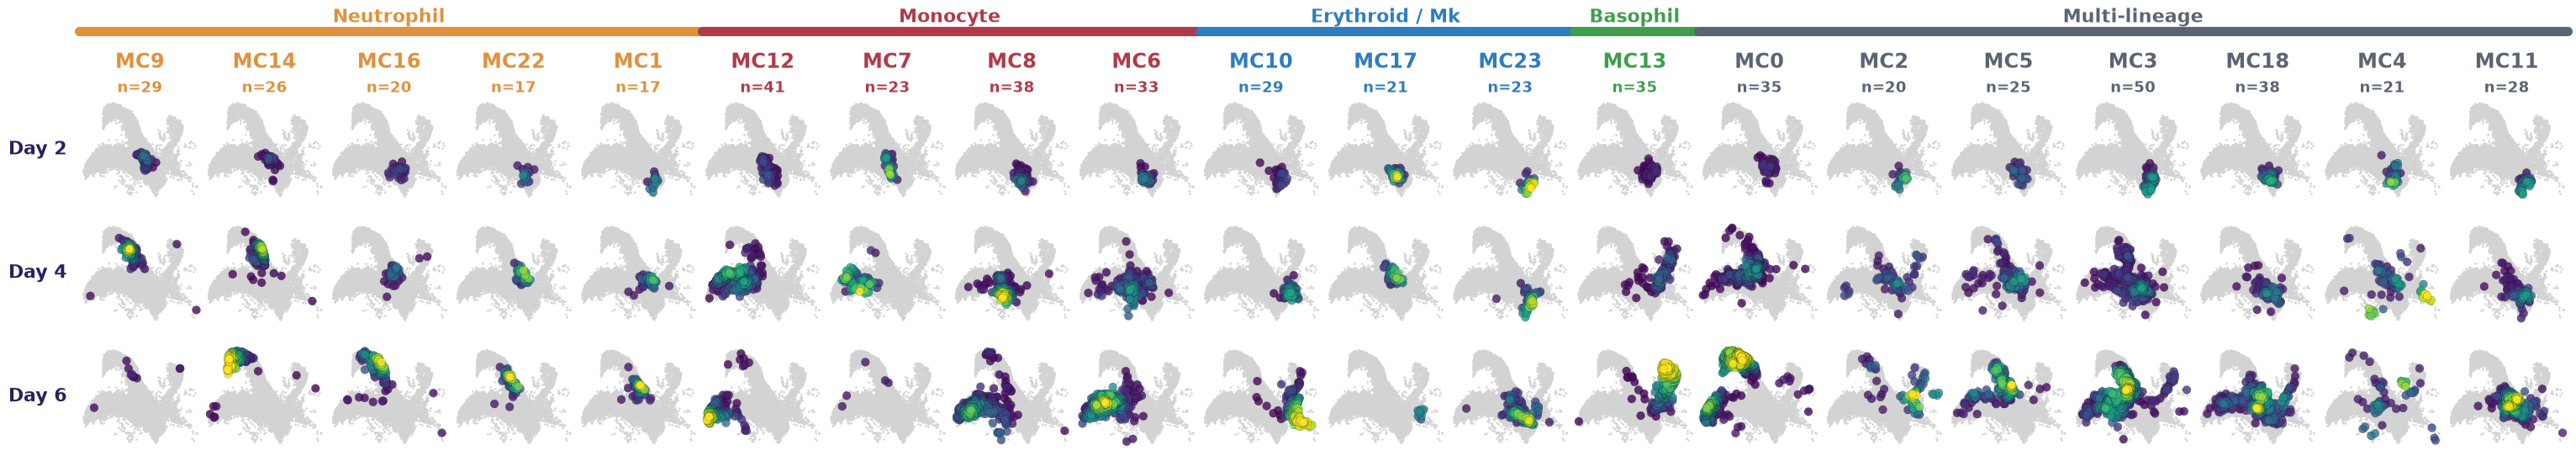

In [33]:
FAM_ACCENT_i = {"Neutrophil": AMBER, "Monocyte": RED, "Erythroid / Mk": "#2E7DBF",
                "Basophil": "#3F9E4D", "Multi-lineage": GREY}

# ===== Panel i (flipped): 3 rows (Day 2, 4, 6) × N columns (metaclones) =====
fig_f = plt.figure(figsize=(1.55 * _nr, 5.5))
gs_f = gridspec.GridSpec(3, _nr, figure=fig_f, wspace=0.02, hspace=-0.05)

for c, m in enumerate(_order_i):
    fcol = FAM_ACCENT_i[_fam_i[m]]
    vmax = _vmax_i[m]
    n_clones = int(Cc[Cc["metaclone"] == m]["LARRY_ID"].nunique())

    for r, day in enumerate(DAYS):
        ax = fig_f.add_subplot(gs_f[r, c])
        ax.scatter(U[:, 0], U[:, 1], s=3.5, c="lightgrey", lw=0, rasterized=True, zorder=0)
        coords, dens, idx = purity_density(m, day)
        if coords is not None:
            o = dens.argsort()
            ax.scatter(coords[o, 0], coords[o, 1], c=dens[o], cmap="viridis", s=50, alpha=0.8,
                       edgecolors="black", linewidths=0.15, vmin=0, vmax=vmax, rasterized=True, zorder=2)

        ax.set_aspect("equal")
        ax.set_xlim(_xmn, _xmx)
        ax.set_ylim(_ymn, _ymx)
        ax.axis("off")

        # Day labels on the left (first column only)
        if c == 0:
            ax.text(-0.10, 0.5, f"Day {day}", transform=ax.transAxes, fontsize=16,
                    color=INK, fontweight="bold", ha="right", va="center")

        # MC label + clone count on top (first row only)
        if r == 0:
            ax.text(0.5, 1.35, f"MC{m}", transform=ax.transAxes, fontsize=17,
                    color=fcol, fontweight="bold", ha="center", va="center")
            ax.text(0.5, 1.10, f"n={n_clones}", transform=ax.transAxes, fontsize=13,
                    color=fcol, fontweight="bold", ha="center", va="center")

# Adjust margins — extra space at top for MC labels + family bars
fig_f.subplots_adjust(left=0.04, right=0.995, top=0.82, bottom=0.005)
fig_f.canvas.draw()

# Family group bars on top (horizontal)
_famcols_f = {}
for c, m in enumerate(_order_i):
    _famcols_f.setdefault(_fam_i[m], []).append(c)

for f, cc in _famcols_f.items():
    left_pos  = fig_f.axes[min(cc) * 3].get_position().x0
    right_pos = fig_f.axes[max(cc) * 3].get_position().x1
    # Horizontal color bar
    bar_y = 0.935
    fig_f.add_artist(plt.Line2D([left_pos, right_pos], [bar_y, bar_y],
                                color=FAM_ACCENT_i[f], lw=8,
                                solid_capstyle="round", transform=fig_f.transFigure))
    # Lineage label above color bar
    fig_f.text((left_pos + right_pos) / 2, bar_y + 0.03, f, rotation=0,
               fontsize=16, color=FAM_ACCENT_i[f], fontweight="bold",
               ha="center", va="center")

tag_f = f"_excl_{'_'.join(map(str, EXCLUDE_MCS))}" if EXCLUDE_MCS else ""
fig_f.savefig(f"{OUTDIR}/panel_2i_density_all_mc_flipped{tag_f}.pdf", dpi=300, bbox_inches="tight")
fig_f.savefig(f"{OUTDIR}/panel_2i_density_all_mc_flipped{tag_f}.png", dpi=600, bbox_inches="tight")
fig_f.savefig(f"{OUTDIR}/panel_2i_density_all_mc_flipped{tag_f}.svg", bbox_inches="tight")

print("saved panel 2i flipped (3 rows × N columns)")

## 10. Outputs

Each panel is saved as **SVG + PDF** (editable text) plus a **PNG** proof in
`../Figure/fig2/panels/`, with per-panel source CSVs in `../Figure/fig2/data/`. No composite is
assembled here — panels are laid out in Illustrator per house convention.

**Panels:** a cell-state UMAP · b clone-family density over time (kNN purity) · c pseudotime +
lineage trajectories + branch masks · d neutrophil-primed pace · e monocyte-primed pace ·
f neutrophil-primed gene analysis · g monocyte-primed gene analysis · h all-metaclone lineage-bias
survey · i all-metaclone density over time.

The final code cell prints the saved panel and source-data paths produced by this run.


In [34]:
import glob
print("PANELS:")
for f in sorted(glob.glob(f"{OUTDIR}/panel_2*.svg")): print("  ",os.path.basename(f))
print("SOURCE DATA:")
for f in sorted(glob.glob(f"{DATADIR}/fig2*.csv")): print("  ",os.path.basename(f))

PANELS:
   panel_2a_celltype_umap.svg
   panel_2b_density_grid.svg
   panel_2c_left_pseudotime_trajectories.svg
   panel_2c_pseudotime_branches.svg
   panel_2d_neu_pace.svg
   panel_2d_neu_pace_left_output.svg
   panel_2d_neu_pace_legend_output.svg
   panel_2d_neu_pace_legend_pace.svg
   panel_2d_neu_pace_right_violins.svg
   panel_2e_mono_pace.svg
   panel_2e_mono_pace_left_output.svg
   panel_2e_mono_pace_legend_output.svg
   panel_2e_mono_pace_legend_pace.svg
   panel_2e_mono_pace_right_violins.svg
   panel_2f_neu_de_heatmap.svg
   panel_2f_neu_genes.svg
   panel_2f_neu_volcano.svg
   panel_2f_neu_volcano_20260728.svg
   panel_2g_mono_de_heatmap.svg
   panel_2g_mono_genes.svg
   panel_2g_mono_volcano.svg
   panel_2g_mono_volcano_20260728.svg
   panel_2h_lineage_bias_map.svg
   panel_2i_density_all_mc.svg
   panel_2i_density_all_mc_flipped.svg
   panel_2i_density_all_mc_flipped_weinreb_endpoints.svg
SOURCE DATA:
   fig2_perday_kruskal_stats.csv
   fig2_source_output_composition.csv
 

saved left panel 2c


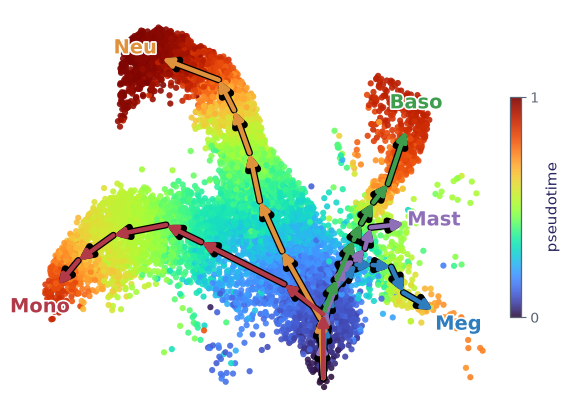

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
import matplotlib.patheffects as patheffects

# Define parameters and waypoints
root_i = int(np.nanargmin(obs["pt"].values))
root_xy = U[root_i]
ptv = obs["pt"].values
BRANCHES = ["Meg", "Mast", "Baso", "Neu", "Mono"]

def branch_waypoints(branch, nbins=7):
    idx = np.where(obs[f"mask_{branch}"].values.astype(bool))[0]
    p = ptv[idx]; xy = U[idx]; edges = np.linspace(np.nanmin(p), np.nanmax(p), nbins + 1); pts = [root_xy]
    for b in range(nbins):
        sel = (p >= edges[b]) & (p < edges[b+1])
        if sel.sum() >= 3:
            pts.append(xy[sel][np.argmin(((xy[sel] - np.median(xy[sel], axis=0))**2).sum(1))])
    return np.array(pts)

def jointed_arrow(ax, pts, color, lw=3.2):
    """Segmented arrow: dark-outlined colored segments with an arrowhead on each segment."""
    for a, b in zip(pts[:-1], pts[1:]):
        # outline
        ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=17, lw=lw + 1.8,
                     color="black", shrinkA=0, shrinkB=0, zorder=4, capstyle="round"))
        # inner colored arrow
        ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=14, lw=lw,
                     color=color, shrinkA=0, shrinkB=0, zorder=5, capstyle="round"))

# Left panel figure
fig, axL = plt.subplots(figsize=(6.5, 5.2))
sc0 = axL.scatter(U[:, 0], U[:, 1], c=ptv, cmap="turbo", s=20, lw=0, alpha=0.9, rasterized=True)

for b in BRANCHES:
    wp = branch_waypoints(b)
    jointed_arrow(axL, wp, BRANCH_COL[b])
    
    # Offset label outward along last segment direction
    d = wp[-1] - wp[-2]
    d = d / (np.hypot(*d) + 1e-9)
    lp = wp[-1] + d * 1.6
    axL.text(lp[0], lp[1], b, fontsize=14, color=BRANCH_COL[b], va="center",
             ha="center", zorder=8, fontweight="bold",
             path_effects=[patheffects.withStroke(linewidth=2.4, foreground="white")])

# Star symbol and root label are hidden (commented out)
# axL.scatter([root_xy[0]], [root_xy[1]], marker="*", s=340, c="white", edgecolors="black", lw=1.5, zorder=7)
# axL.text(root_xy[0], root_xy[1]-1.2, "root", fontsize=11, color=INK, ha="center", va="top", zorder=7)

axL.set_aspect("equal")
axL.axis("off")
# axL.set_title("Palantir pseudotime + lineage trajectories", loc="left", fontsize=14, pad=6)

cb = fig.colorbar(sc0, ax=axL, fraction=0.035, pad=0.01, shrink=0.55)
cb.set_label("pseudotime", fontsize=11)
cb.ax.tick_params(labelsize=10)
cb.set_ticks([ptv.min(), ptv.max()])
cb.set_ticklabels(["0", "1"])

fig.savefig(f"{OUTDIR}/panel_2c_left_pseudotime.pdf", dpi=300, bbox_inches="tight")
fig.savefig(f"{OUTDIR}/panel_2c_left_pseudotime.png", dpi=190, bbox_inches="tight")

print("saved left panel 2c")
if "host" in globals() and hasattr(host, "view_image"):
    host.view_image(f"{OUTDIR}/panel_2c_left_pseudotime.png")

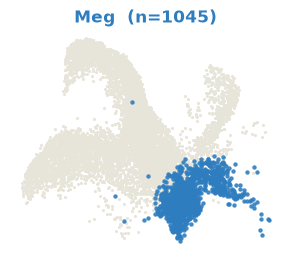

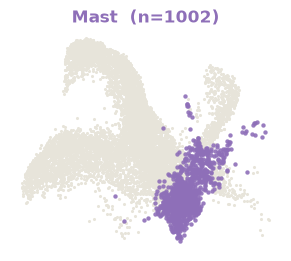

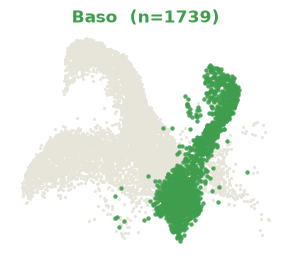

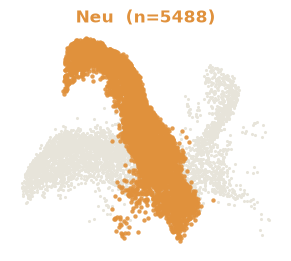

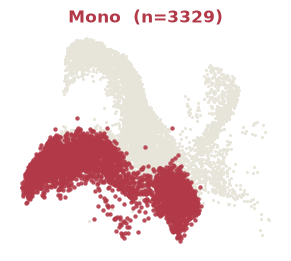

saved individual branch plots (Meg, Mast, Baso, Neu, Mono)


In [ ]:
import matplotlib.pyplot as plt

# Output each branch plot one at a time
for b in BRANCHES:
    fig, ax = plt.subplots(figsize=(3.5, 3.5))
    m = obs[f"mask_{b}"].values.astype(bool)
    
    # Background unselected cells
    ax.scatter(U[~m, 0], U[~m, 1], s=5, c="#E7E4DA", lw=0, rasterized=True)
    # Selected branch cells
    ax.scatter(U[m, 0], U[m, 1], s=10, c=BRANCH_COL[b], lw=0, alpha=0.9, rasterized=True)
    
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{b}  (n={int(m.sum())})", fontsize=12, color=BRANCH_COL[b], fontweight="bold", pad=4)
    
    # Save individual branch figures
    fig.savefig(f"{OUTDIR}/panel_2c_branch_{b}.pdf", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUTDIR}/panel_2c_branch_{b}.png", dpi=190, bbox_inches="tight")
    
    plt.show()

print("saved individual branch plots (Meg, Mast, Baso, Neu, Mono)")

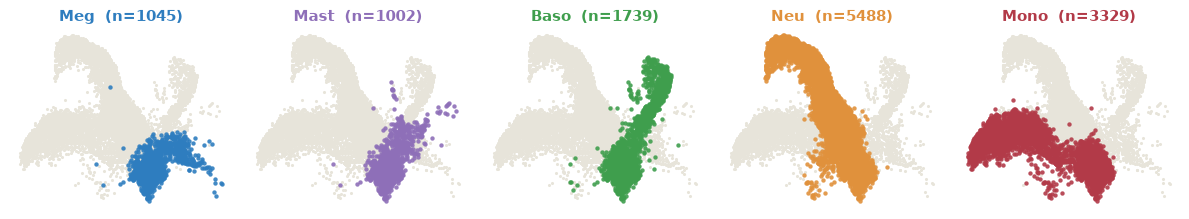

saved panel 2c right branches (1x5 row layout)


In [37]:
import matplotlib.pyplot as plt

# 1 row x 5 columns layout for all 5 branches
fig, axes = plt.subplots(1, 5, figsize=(12.0, 2.7))

for ax, b in zip(axes, BRANCHES):
    m = obs[f"mask_{b}"].values.astype(bool)
    
    # Background unselected cells
    ax.scatter(U[~m, 0], U[~m, 1], s=5, c="#E7E4DA", lw=0, rasterized=True)
    # Selected branch cells
    ax.scatter(U[m, 0], U[m, 1], s=10, c=BRANCH_COL[b], lw=0, alpha=0.9, rasterized=True)
    
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{b}  (n={int(m.sum())})", fontsize=11, color=BRANCH_COL[b], fontweight="bold", pad=4)

plt.tight_layout()

# Save outputs
fig.savefig(f"{OUTDIR}/panel_2c_branches_1x5.pdf", dpi=300, bbox_inches="tight")
fig.savefig(f"{OUTDIR}/panel_2c_branches_1x5.png", dpi=190, bbox_inches="tight")

plt.show()

print("saved panel 2c right branches (1x5 row layout)")
if "host" in globals() and hasattr(host, "view_image"):
    host.view_image(f"{OUTDIR}/panel_2c_branches_1x5.png")